<a href="https://colab.research.google.com/github/aymanr8-dot/DS-2002-Walmart-Hurricane-Project_Data-Demons-/blob/main/notebooks/scratch/Walmart_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics — DS 2002 Midterm
**Team Data Demons** · Esther & Ayman · Fall 2026

**Scope of this notebook:** the data cleaning pipeline, the weather API and join, and **all five questions**.

**The situation.** The transactions cover **September 1–30, 2024** across 12 Florida stores. That window contains
**Hurricane Helene**: the National Hurricane Center began advisories on *Potential Tropical Cyclone Nine* on
**Sept 23**, and Helene made landfall in the Big Bend near Perry, FL, as a Category 4 at about **11 pm EDT on Sept 26**.

**How to run:** `Runtime → Restart and run all` (Colab) or `Kernel → Restart & Run All` (Jupyter).
Data is read straight from the team repo on GitHub, so the notebook runs anywhere with internet access.
The weather call uses Open-Meteo, which needs no API key.

| Section | What it does |
|---|---|
| 0 | Setup and data loading |
| 1 | Cleaning pipeline (functions), row counts before/after |
| 2 | Profile raw vs. clean, five worst problems, SKU consolidation, decision log |
| 3 | Weather API (retries, timezone alignment, checked join) |
| 4 | **Q1** Demand surge |
| 5 | **Q2** SKU consolidation |
| 6 | **Q3** Weather correlation and lag |
| 7 | **Q4** Stores and geography (plus distribution-center capacity) |
| 8 | **Q5** Signal or artifact: the board-game spike (SQL on the inventory database) |
| 9 | What we tell leadership |

## 0. Setup

In [1]:
import os, re, time, json, sqlite3, urllib.parse, urllib.request
from datetime import date

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ---- Analysis constants (every one of these is a decision; see the decision log) ----
BASELINE_START, BASELINE_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-14")
LANDFALL_DATE = pd.Timestamp("2024-09-26")     # Helene landfall, ~11 pm EDT
NHC_FIRST_ADVISORY = pd.Timestamp("2024-09-23")  # Potential Tropical Cyclone Nine
SURGE_SEARCH_START = pd.Timestamp("2024-09-15")  # first day after the baseline
DATA_DIR = "data"                                # local folder for the weather cache
os.makedirs(DATA_DIR, exist_ok=True)

# ---- Chart style: one validated categorical order, thin marks, recessive grid ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.8), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False, "lines.linewidth": 2, "axes.axisbelow": True,
})

def shade_windows(ax, alpha=0.10):
    """Shade the baseline and the storm-approach windows on a date axis."""
    ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1), color=MUTED, alpha=alpha, lw=0)
    ax.axvline(LANDFALL_DATE + pd.Timedelta(hours=23), color="#52514e", ls="--", lw=1)
    ymax = ax.get_ylim()[1]
    ax.text(BASELINE_START + pd.Timedelta(hours=6), ymax * 0.97, "baseline", va="top", fontsize=9, color="#52514e")
    ax.text(LANDFALL_DATE + pd.Timedelta(hours=28), ymax * 0.97, "landfall", va="top", ha="left", fontsize=9, color="#52514e")

## 1. Cleaning pipeline
One function per problem, chained in `clean_transactions()`. Every function writes its decision and the rows it touched
to `decision_log`. Nothing is silently dropped except exact duplicates: returns and rows with no timestamp are **kept and flagged**.

In [2]:
import re
import numpy as np
import pandas as pd

DATA_URL = ('https://raw.githubusercontent.com/aymanr8-dot/DS-2002-Midterm-Project-Data-Demons-/'
            'main/notebooks/06-midterm-walmart/data/')

raw = pd.read_csv(DATA_URL + 'walmart_transactions.csv', dtype=str)
stores_raw = pd.read_csv(DATA_URL + 'store_locations.csv', dtype=str)

decision_log = []

def log_decision(step, decision, rows_touched, rows_after):
    decision_log.append({'step': step, 'decision': decision,
                         'rows_touched': int(rows_touched), 'rows_after': int(rows_after)})

def drop_duplicates(df):
    dupes = df.duplicated()
    out = df[~dupes].copy()
    log_decision('duplicates', 'Dropped exact duplicate rows (same transaction_id and every field)',
                 dupes.sum(), len(out))
    return out

def clean_store_id(s):
    """' FL-330', 'FL_330', 'FL330', 'fl-330' -> 'FL-330'"""
    s = s.astype(str).str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^([A-Z]{2})(\d+)$', r'\1-\2', regex=True)

def standardize_store_ids(df):
    before = df['store_id']
    df['store_id'] = clean_store_id(before)
    log_decision('store_id', f"Stripped spaces, upper-cased, rewrote to FL-### "
                 f"({before.nunique()} spellings -> {df['store_id'].nunique()} stores)",
                 (before != df['store_id']).sum(), len(df))
    return df

def parse_unit_price(df):
    had_dollar = df['unit_price'].str.contains(r'\$', na=False)
    df['unit_price'] = pd.to_numeric(df['unit_price'].str.replace(r'[$,\s]', '', regex=True),
                                     errors='coerce')
    assert df['unit_price'].notna().all(), 'some unit_price values did not convert'
    log_decision('unit_price', "Removed leading '$' and converted text to float",
                 had_dollar.sum(), len(df))
    return df

def flag_returns(df):
    df['quantity'] = pd.to_numeric(df['quantity']).astype(int)
    df['is_return'] = df['quantity'] < 0
    log_decision('quantity', 'Negative quantities treated as returns: kept, flagged is_return=True, '
                 'excluded from demand counts', df['is_return'].sum(), len(df))
    return df

TS_FORMATS = ['%Y-%m-%d %H:%M:%S',   # 2024-09-13 20:30:20
              '%Y-%m-%dT%H:%M:%S',   # 2024-09-24T09:48:13
              '%m/%d/%Y %H:%M',      # 09/26/2024 09:26
              '%m-%d-%Y %H:%M:%S',   # 09-23-2024 18:24:47
              '%d-%b-%Y %H:%M']      # 21-Sep-2024 19:46

def parse_timestamps(df):
    s = df['timestamp'].str.strip()
    parsed = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        parsed = parsed.fillna(pd.to_datetime(s, format=fmt, errors='coerce'))
    unparsed = s.notna() & parsed.isna()
    assert unparsed.sum() == 0, f'{unparsed.sum()} timestamps in an unknown format'
    reformatted = s.notna() & ~s.str.match(r'^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$', na=False)
    df['timestamp'] = parsed
    log_decision('timestamp', f'Parsed {len(TS_FORMATS)} text formats to datetime (store-local time)',
                 reformatted.sum(), len(df))
    df['timestamp_missing'] = df['timestamp'].isna()
    log_decision('timestamp', 'Missing timestamps flagged (timestamp_missing=True), not dropped: still count '
                 'for SKU/product totals, left out of anything time-based', df['timestamp_missing'].sum(), len(df))
    return df

CATEGORY_MAP = {'emergency': 'Emergency', 'emergency supplies': 'Emergency',
                'grocery': 'Grocery', 'groceries': 'Grocery',
                'electronics': 'Electronics',
                'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
                'household': 'Household', 'household essentials': 'Household',
                'baby': 'Baby', 'baby products': 'Baby',
                'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
                'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
                'snacks': 'Snacks',
                'health': 'Health', 'health & wellness': 'Health'}

def standardize_categories(df):
    before = df['category']
    df['category'] = before.str.strip().str.lower().map(CATEGORY_MAP)
    assert df['category'].notna().all(), 'unmapped category label'
    log_decision('category', f"Mapped {before.nunique()} category spellings to {df['category'].nunique()} categories",
                 (before != df['category']).sum(), len(df))
    df['product_name'] = df['product_name'].str.strip()
    return df

STORE_TZ = {'FL-710': 'America/Chicago'}   # Pensacola is on Central time; every other store is Eastern

def clean_stores(stores):
    s = stores.copy()
    s['store_id'] = clean_store_id(s['store_id'])
    s = s.drop_duplicates('store_id').copy()            # FL239 / FL_287 were repeat rows
    s['state'] = 'FL'                                    # 'Florida', 'Fla.' -> 'FL'
    s['region'] = s['region'].str.strip()
    s[['latitude', 'longitude']] = s[['latitude', 'longitude']].astype(float)
    tlh = s['store_id'] == 'FL-619'                      # Tallahassee had blank coordinates (filled with city center)
    s.loc[tlh, ['latitude', 'longitude']] = [30.4383, -84.2807]
    s['tz'] = s['store_id'].map(STORE_TZ).fillna('America/New_York')
    return s.reset_index(drop=True)

def clean_transactions(df):
    df = drop_duplicates(df)
    df = standardize_store_ids(df)
    df = parse_unit_price(df)
    df = flag_returns(df)
    df = parse_timestamps(df)
    df = standardize_categories(df)
    return df.reset_index(drop=True)

sales = clean_transactions(raw)
stores = clean_stores(stores_raw)

print(f'rows before cleaning: {len(raw):,}')
print(f'rows after cleaning:  {len(sales):,}')
print(f'rows removed:         {len(raw) - len(sales):,}')
print(f"returns flagged (kept): {sales['is_return'].sum():,}")
print(f"missing timestamps flagged (kept): {sales['timestamp_missing'].sum():,}")
print(f"store file: {len(stores_raw)} rows -> {len(stores)} stores after dedupe")
unjoined = set(sales['store_id']) - set(stores['store_id'])
print('store_ids that do not join to the store file:', unjoined or 'none')
print('date range:', sales['timestamp'].min(), 'to', sales['timestamp'].max())
sales.head()

rows before cleaning: 25,562
rows after cleaning:  25,532
rows removed:         30
returns flagged (kept): 130
missing timestamps flagged (kept): 884
store file: 14 rows -> 12 stores after dedupe
store_ids that do not join to the store file: none
date range: 2024-09-01 06:01:15 to 2024-09-30 22:57:47


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,is_return,timestamp_missing
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,False,False
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,Grocery,1,2.02,False,False
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,False,False
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,False,False
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcohol,3,18.82,False,False


## 2. Profile: raw vs. clean
The cleaning functions copy the data, so `raw` is still the untouched file. Profiling both side by side shows each fix landed.

In [3]:
NULL_TOKENS = {"", "NULL", "N/A", "NA", "NaN", "nan", "None", "null"}

def profile(df, name="df"):
    """Rows, columns, types, nulls (counting text null tokens), distinct values, and a few examples per column."""
    out = []
    for c in df.columns:
        s = df[c]
        is_null = s.isna() | s.astype(str).str.strip().isin(NULL_TOKENS)
        out.append({
            "column": c,
            "dtype": str(s.dtype),
            "null_pct": round(100 * is_null.mean(), 2),
            "distinct": s[~is_null].nunique(),
            "examples": list(s[~is_null].drop_duplicates().head(4)),
        })
    print(f"{name}: {len(df):,} rows x {df.shape[1]} cols | exact duplicate rows: {df.duplicated().sum()}")
    return pd.DataFrame(out).set_index("column")

display(profile(raw, "walmart_transactions (raw)"))
display(profile(sales, "sales (clean)"))

walmart_transactions (raw): 25,562 rows x 8 cols | exact duplicate rows: 30


,dtype,null_pct,distinct,examples
column,,,,
transaction_id,object,0.00,25532,"[TXN012636, TXN000759, TXN003338, TXN025020]"
store_id,object,0.00,60,"[FL-710, fl-412, FL-105, FL-330]"
timestamp,object,3.47,23952,"[2024-09-24T09:48:13, 2024-09-13 20:30:20, 202..."
sku,object,0.00,45,"[PNUTBTR-16, CNSOUP-01, TOILETPAPER12, ROKU-STD]"
product_name,object,0.00,63,"[PEANUT BUTTER, CANNED SOUP, Toilet Paper 12-R..."
category,object,0.00,37,"[Grocery, GROCERY, Household Essentials, ELECT..."
quantity,object,0.00,11,"[1, 2, 3, 4]"
unit_price,object,0.00,3668,"[3.15, 2.02, 10.47, 28.59]"


sales (clean): 25,532 rows x 10 cols | exact duplicate rows: 0


,dtype,null_pct,distinct,examples
column,,,,
transaction_id,object,0.00,25532,"[TXN012636, TXN000759, TXN003338, TXN025020]"
store_id,object,0.00,12,"[FL-710, FL-412, FL-105, FL-330]"
timestamp,datetime64[ns],3.46,23417,"[2024-09-24 09:48:13, 2024-09-13 20:30:20, 202..."
sku,object,0.00,45,"[PNUTBTR-16, CNSOUP-01, TOILETPAPER12, ROKU-STD]"
product_name,object,0.00,62,"[PEANUT BUTTER, CANNED SOUP, Toilet Paper 12-R..."
category,object,0.00,10,"[Grocery, Household, Electronics, Alcohol]"
quantity,int64,0.00,11,"[1, 2, 3, 4]"
unit_price,float64,0.00,1667,"[3.15, 2.02, 10.47, 28.59]"
is_return,bool,0.00,2,"[False, True]"


In [4]:
ts_shapes = raw["timestamp"].str.replace(r"\d", "9", regex=True).value_counts(dropna=False)
print("Raw timestamp shapes (digits replaced by 9; NaN = empty/NULL/N/A/NaN/nan):\n", ts_shapes, "\n")
print("store_id spellings:", raw["store_id"].nunique(), "->", sales["store_id"].nunique())
print("category spellings:", raw["category"].nunique(), "->", sales["category"].nunique())
print("product_name spellings:", raw["product_name"].nunique(), "| SKUs:", raw["sku"].nunique())
print("unit_price with $ sign:", raw["unit_price"].str.contains(r"\$").sum())
display(profile(stores_raw, "store_locations (raw)"))

Raw timestamp shapes (digits replaced by 9; NaN = empty/NULL/N/A/NaN/nan):
 timestamp
9999-99-99 99:99:99    12179
99/99/9999 99:99        5031
99-Sep-9999 99:99       2546
9999-99-99T99:99:99     2511
99-99-9999 99:99:99     2409
NaN                      886
Name: count, dtype: int64 

store_id spellings: 60 -> 12
category spellings: 37 -> 10
product_name spellings: 63 | SKUs: 45
unit_price with $ sign: 3029
store_locations (raw): 14 rows x 8 cols | exact duplicate rows: 0


,dtype,null_pct,distinct,examples
column,,,,
store_id,object,0.00,14,"[FL-239, FL-105, FL-330, FL-412]"
store_name,object,0.00,12,"[Walmart Supercenter Orlando, Walmart Supercen..."
city,object,0.00,12,"[Orlando, Tampa, Miami, Jacksonville]"
state,object,0.00,3,"[FL, Florida, Fla.]"
zip_code,object,0.00,12,"[32801, 33602, 33101, 32099]"
latitude,object,7.14,11,"[28.5383, 27.9506, 25.7617, 30.3322]"
longitude,object,7.14,11,"[-81.3792, -82.4572, -80.1918, -81.6557]"
region,object,0.00,7,"[Central, West, South, North]"


### The five worst problems (from the profile)
1. **Timestamps come in five formats plus five spellings of "missing".** `2024-09-12 08:15:00`, `2024-09-12T08:15:00`, `09/12/2024 08:15`, `12-Sep-2024 08:15`, `09-12-2024 08:15:00`, and 886 rows (3.5%) that are empty, `NULL`, `N/A`, `NaN` or `nan`. Q1 and Q3 both run on dates, so this comes first.
2. **The same product sits under several SKUs.** 45 SKUs, but only 20 real products. Strawberry Pop-Tarts alone appears as `PT-12`, `SKU#459812`, `POPTART-STRAW` and `PT_STRAWBERRY`. The product name is spelled 63 ways.
3. **`store_id` has 60 spellings for 12 stores.** `FL-239`, `fl-239`, `FL_239`, `FL239`, and `" FL-239"` with a leading space. The store file itself has two duplicate stores (`FL239`, `FL_287`), and Tallahassee has no coordinates.
4. **`category` has 37 spellings for 10 categories.** Case (`EMERGENCY` / `emergency`) and synonyms (`Emergency Supplies`, `Groceries`, `Games & Entertainment`, `Alcoholic Beverages`, `Baby Products`).
5. **Numbers stored as text.** `unit_price` is text, and 3,029 values (12%) start with `$`. `quantity` has 130 negative values (returns), and 30 rows are exact duplicates.

### 2.1 SKU consolidation mapping (needed by Q2)
**Method.** In the transaction file, each SKU is sold under several product-name spellings, and those spellings are *shared*
across SKUs (`HD Tarp` appears under both `TARP-HD` and `HDTARP-01`). We link SKUs that share a normalized product name
(a union-find over the SKU–name graph). Each connected group is one real product. This is data-driven, so we don't have to
guess that `PT-12` and `SKU#459812` are the same Pop-Tart: the cashiers' name strings tell us. We then review every group by
hand and give it a canonical name.

In [5]:
def norm_text(s):
    return s.astype(str).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

def build_sku_map(tx, catalog):
    """Group SKUs that share a normalized product name in POS data; return one row per SKU."""
    pairs = pd.DataFrame({"sku": tx["sku"].str.strip().str.upper(), "name": norm_text(tx["product_name"])}).drop_duplicates()
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in pairs.itertuples(index=False):
        a, b = find("S:" + sku), find("N:" + name)
        if a != b:
            parent[a] = b
    skus = sorted(set(pairs["sku"]) | set(catalog["sku"].str.strip().str.upper()))
    groups = {}
    for sku in skus:
        groups.setdefault(find("S:" + sku), []).append(sku)
    return groups

# Hand-reviewed canonical names, keyed by any one SKU in the group
CANONICAL = {
    "PT-12": ("P01", "Pop-Tarts Strawberry"),        "WTR-24": ("P02", "Bottled Water 24-Pack"),
    "BATT-100": ("P03", "AA Batteries 4-Pack"),      "FLASH-01": ("P04", "LED Flashlight"),
    "BEER-24": ("P05", "Light Beer 24-Pack"),        "BG-MONO": ("P06", "Monopoly Board Game"),
    "CARDS-01": ("P07", "Playing Cards"),            "STREAM-01": ("P08", "Roku Streaming Stick"),
    "SOUP-CAN": ("P09", "Canned Soup"),              "BREAD-WH": ("P10", "White Bread"),
    "PB-16": ("P11", "Peanut Butter 16oz"),          "CNDL-EM": ("P12", "Emergency Candles"),
    "FAID-01": ("P13", "First Aid Kit"),             "CHRG-PORT": ("P14", "Portable Phone Charger"),
    "CHIPS-VP": ("P15", "Chips Variety Pack"),       "PTOWEL-6": ("P16", "Paper Towels 6-Roll"),
    "TP-12": ("P17", "Toilet Paper 12-Roll"),        "DIAP-S3": ("P18", "Diapers Size 3"),
    "BFORM-01": ("P19", "Infant Formula"),           "TARP-HD": ("P20", "Heavy Duty Tarp"),
}

def sku_mapping_table(tx_raw, cat_raw):
    groups = build_sku_map(tx_raw, cat_raw)
    rows = []
    for members in groups.values():
        keys = [s for s in members if s in CANONICAL]
        assert len(keys) == 1, f"group {members} needs exactly one canonical entry, found {keys}"
        pid, pname = CANONICAL[keys[0]]
        rows += [{"sku": s, "product_id": pid, "product": pname, "skus_in_group": len(members)} for s in members]
    m = pd.DataFrame(rows).sort_values(["product_id", "sku"]).reset_index(drop=True)
    # Category per product: normalize every category label seen for its SKUs; it must be unanimous.
    t = pd.DataFrame({"sku": tx_raw["sku"].str.strip().str.upper(), "category": norm_text(tx_raw["category"]).map(CATEGORY_MAP)})
    cat = t.merge(m, on="sku").groupby("product_id")["category"].agg(lambda x: sorted(x.dropna().unique()))
    assert (cat.str.len() == 1).all(), f"products with conflicting categories:\n{cat[cat.str.len() != 1]}"
    m["category"] = m["product_id"].map(cat.str[0])
    return m

catalog_raw = pd.read_csv(DATA_URL + 'product_catalog.csv', dtype=str)
SKU_MAP = sku_mapping_table(raw, catalog_raw)
print(f"{SKU_MAP['sku'].nunique()} SKUs -> {SKU_MAP['product_id'].nunique()} products")
SKU_MAP

45 SKUs -> 20 products


,sku,product_id,product,skus_in_group,category
0,POPTART-STRAW,P01,Pop-Tarts Strawberry,4,Breakfast
1,PT-12,P01,Pop-Tarts Strawberry,4,Breakfast
2,PT_STRAWBERRY,P01,Pop-Tarts Strawberry,4,Breakfast
3,SKU#459812,P01,Pop-Tarts Strawberry,4,Breakfast
4,WATER24PK,P02,Bottled Water 24-Pack,3,Emergency
5,WTR-24,P02,Bottled Water 24-Pack,3,Emergency
6,WTR_24PK,P02,Bottled Water 24-Pack,3,Emergency
7,BAT-AA4,P03,AA Batteries 4-Pack,3,Emergency
8,BATT-100,P03,AA Batteries 4-Pack,3,Emergency
9,BATT_AA_4PK,P03,AA Batteries 4-Pack,3,Emergency


### 2.2 Apply the mapping and finish the analysis table
Adds the canonical product to every row, a calendar `date`, and `revenue`. Also logs the store-file fixes made inside
`clean_stores()`, so the decision log covers every file we touched.

In [6]:
n_before = len(sales)
sales = sales.merge(SKU_MAP[["sku", "product_id", "product", "category"]].rename(columns={"category": "product_category"}),
                    on="sku", how="left", validate="many_to_one")
assert len(sales) == n_before and sales["product_id"].notna().all(), "SKU mapping changed the row count or left a SKU unmapped"
assert (sales["category"] == sales["product_category"]).all(), "row category disagrees with the product's category"
sales = sales.drop(columns="product_category")
sales["product_name_raw"] = sales["product_name"]
sales["product_name"] = sales["product"]
sales = sales.drop(columns="product")
log_decision("sku", f"Mapped {sales['sku'].nunique()} SKUs to {sales['product_id'].nunique()} products via SKU_MAP; "
             "canonical name in product_name, original kept in product_name_raw",
             (sales["product_name_raw"] != sales["product_name"]).sum(), len(sales))

sales["date"] = sales["timestamp"].dt.normalize()
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# Store-file decisions made inside clean_stores()
log_decision("stores", "Normalized store ids and dropped repeat stores (FL239 = FL-239, FL_287 = FL-287)",
             len(stores_raw) - len(stores), len(stores))
log_decision("stores", "Set state 'Florida' / 'Fla.' to 'FL'", (stores_raw["state"] != "FL").sum(), len(stores))
log_decision("stores", "FL-619 Tallahassee had blank lat/lon: filled with city-center coordinates so the weather API can be called",
             stores_raw["latitude"].isna().sum(), len(stores))
log_decision("stores", "Added each store's timezone: Pensacola FL-710 is Central, the rest are Eastern", len(stores), len(stores))

# Analysis views used by Q1-Q3
demand = sales[~sales["is_return"]]                      # units sold (returns excluded)
dated_sales = demand[~demand["timestamp_missing"]]       # ... that also have a usable date

# Catalog with the canonical product attached (Q2 uses it to show the catalog's internal conflicts)
catalog = catalog_raw.assign(sku=catalog_raw["sku"].str.strip().str.upper()).merge(
    SKU_MAP[["sku", "product_id", "product"]], on="sku", how="left", validate="one_to_one")
catalog = catalog.rename(columns={"category": "category_raw"})
catalog["unit_cost"] = pd.to_numeric(catalog["unit_cost"])
assert catalog["product_id"].notna().all()

pd.Series({
    "rows": len(sales), "stores": sales["store_id"].nunique(), "SKUs": sales["sku"].nunique(),
    "products": sales["product_id"].nunique(), "categories": sales["category"].nunique(),
    "returns (kept, flagged)": int(sales["is_return"].sum()),
    "no timestamp (kept, flagged)": int(sales["timestamp_missing"].sum()),
    "rows used for by-date analysis": len(dated_sales),
}).to_frame("clean table")

,clean table
rows,25532
stores,12
SKUs,45
products,20
categories,10
"returns (kept, flagged)",130
"no timestamp (kept, flagged)",884
rows used for by-date analysis,24521


### 2.3 Decision log

In [7]:
with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame(decision_log))

,step,decision,rows_touched,rows_after
0,duplicates,Dropped exact duplicate rows (same transaction_id and every field),30,25532
1,store_id,"Stripped spaces, upper-cased, rewrote to FL-### (60 spellings -> 12 stores)",4345,25532
2,unit_price,Removed leading '$' and converted text to float,3026,25532
3,quantity,"Negative quantities treated as returns: kept, flagged is_return=True, excluded from demand counts",130,25532
4,timestamp,Parsed 5 text formats to datetime (store-local time),12479,25532
5,timestamp,"Missing timestamps flagged (timestamp_missing=True), not dropped: still count for SKU/product totals, left out of anything time-based",884,25532
6,category,Mapped 37 category spellings to 10 categories,18744,25532
7,sku,"Mapped 45 SKUs to 20 products via SKU_MAP; canonical name in product_name, original kept in product_name_raw",17319,25532
8,stores,"Normalized store ids and dropped repeat stores (FL239 = FL-239, FL_287 = FL-287)",2,12
9,stores,Set state 'Florida' / 'Fla.' to 'FL',4,12


### 2.4 Daily order volume
A sanity check before any question: what does a normal day look like, and when does the data start moving?

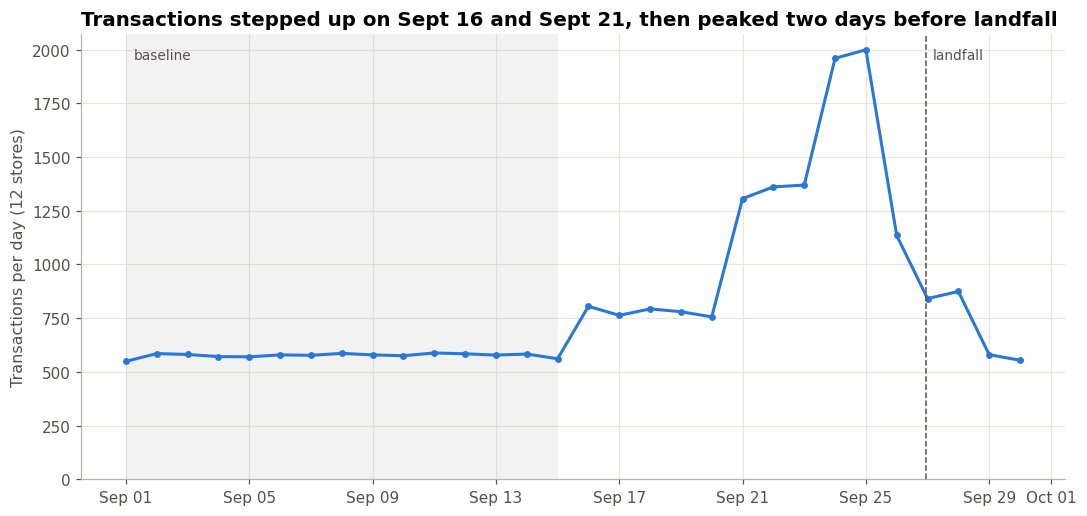

In [8]:
daily_orders = dated_sales.groupby("date")["transaction_id"].nunique()

fig, ax = plt.subplots()
ax.plot(daily_orders.index, daily_orders.values, color=PALETTE[0], marker="o", ms=3.5)
ax.set_title("Transactions stepped up on Sept 16 and Sept 21, then peaked two days before landfall")
ax.set_ylabel("Transactions per day (12 stores)")
ax.set_xlabel("")
ax.set_ylim(0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
shade_windows(ax)
plt.tight_layout(); plt.show()

## 3. Weather API: Open-Meteo historical archive
**Source:** `https://archive-api.open-meteo.com/v1/archive` (ERA5 reanalysis, no key needed).

**Timezone handling.** We request hourly data **in GMT on purpose** (`timezone=GMT`), the same way the case's weather feed
arrived. Then we convert each store's hours to that store's own local time before rolling up to calendar days. Sales
timestamps are local store time, so a storm hour at 02:00 GMT on Sept 27 is 10 pm EDT on **Sept 26** in Orlando, and 9 pm CDT
in Pensacola. Rolling up in GMT would push late-evening weather into the wrong sales day.

In [9]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
HOURLY_VARS = ["precipitation", "wind_speed_10m", "wind_gusts_10m", "pressure_msl"]
WEATHER_CACHE = os.path.join(DATA_DIR, "weather_hourly_gmt_cache.csv")

def fetch_hourly_weather(lat, lon, start, end, retries=4, backoff=2.0, timeout=30):
    """One Open-Meteo archive call with retries and exponential backoff. Returns hourly rows with a GMT timestamp."""
    params = {
        "latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
        "hourly": ",".join(HOURLY_VARS), "timezone": "GMT",
        "wind_speed_unit": "mph", "precipitation_unit": "inch",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ARCHIVE_URL, params=params, timeout=timeout)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status()
            payload = r.json()
            break
        except (requests.RequestException, ValueError) as e:
            if attempt == retries:
                raise
            wait = backoff ** attempt
            print(f"  attempt {attempt} failed ({e}); retrying in {wait:.0f}s")
            time.sleep(wait)
    assert payload.get("utc_offset_seconds", 0) == 0, "expected GMT timestamps from the API"
    h = pd.DataFrame(payload["hourly"])
    h["time_gmt"] = pd.to_datetime(h.pop("time")).dt.tz_localize("UTC")
    h["source"] = f"open-meteo archive ({ARCHIVE_URL})"
    return h

def get_store_weather(stores, start="2024-08-31", end="2024-10-01"):
    """Hourly GMT weather for every store. One day of padding each side so local days at the edges are complete."""
    frames = []
    try:
        for s in stores.itertuples():
            h = fetch_hourly_weather(s.latitude, s.longitude, start, end)
            h["store_id"] = s.store_id
            frames.append(h)
            time.sleep(0.3)   # be polite to a free API
        hourly = pd.concat(frames, ignore_index=True)
        hourly.to_csv(WEATHER_CACHE, index=False)   # cache of a real call, used only if a later run can't reach the API
    except Exception as e:
        if not os.path.exists(WEATHER_CACHE):
            raise
        print(f"API unavailable ({e}); loading cache of a previous successful call: {WEATHER_CACHE}")
        hourly = pd.read_csv(WEATHER_CACHE)
        hourly["time_gmt"] = pd.to_datetime(hourly["time_gmt"], utc=True)
        hourly["source"] = hourly["source"] + " [cached]"
    return hourly

def hourly_to_local_daily(hourly, stores):
    """Convert GMT hours to each store's local time, then roll up to local calendar days."""
    h = hourly.merge(stores[["store_id", "tz"]], on="store_id", how="left", validate="many_to_one")
    h["time_local"] = [t.tz_convert(z).tz_localize(None) for t, z in zip(h["time_gmt"], h["tz"])]
    h["date"] = h["time_local"].dt.normalize()
    d = (h.groupby(["store_id", "date"])
           .agg(precip_in=("precipitation", "sum"),
                max_wind_mph=("wind_speed_10m", "max"),
                max_gust_mph=("wind_gusts_10m", "max"),
                min_pressure_hpa=("pressure_msl", "min"),
                hours=("time_local", "size"),
                source=("source", "first"))
           .reset_index())
    d = d[d["date"].between("2024-09-01", "2024-09-30")]
    assert (d["hours"] >= 23).all() and (d["hours"] <= 25).all(), "incomplete local days after timezone conversion"
    return d.reset_index(drop=True)

weather_hourly = get_store_weather(stores)
weather_daily = hourly_to_local_daily(weather_hourly, stores)
print(f"hourly rows: {len(weather_hourly):,} | daily rows: {len(weather_daily)} (expected 12 stores x 30 days = 360)")
weather_daily.head()

hourly rows: 9,216 | daily rows: 360 (expected 12 stores x 30 days = 360)


,store_id,date,precip_in,max_wind_mph,max_gust_mph,min_pressure_hpa,hours,source
0,FL-078,2024-09-01,0.059,7.0,21.5,1011.9,24,open-meteo archive (https://archive-api.open-m...
1,FL-078,2024-09-02,0.114,5.1,17.0,1011.9,24,open-meteo archive (https://archive-api.open-m...
2,FL-078,2024-09-03,0.315,10.1,22.1,1013.9,24,open-meteo archive (https://archive-api.open-m...
3,FL-078,2024-09-04,0.614,9.5,21.3,1016.8,24,open-meteo archive (https://archive-api.open-m...
4,FL-078,2024-09-05,0.525,8.6,18.1,1015.4,24,open-meteo archive (https://archive-api.open-m...


In [10]:
# Show the timezone shift with one real hour: the same GMT hour lands on different local dates.
ex = weather_hourly[(weather_hourly["time_gmt"] == pd.Timestamp("2024-09-27 02:00", tz="UTC")) &
                    weather_hourly["store_id"].isin(["FL-239", "FL-710"])].merge(stores[["store_id", "city", "tz"]], on="store_id")
ex["local_time"] = [t.tz_convert(z) for t, z in zip(ex["time_gmt"], ex["tz"])]
ex[["store_id", "city", "time_gmt", "local_time", "wind_gusts_10m"]]

,store_id,city,time_gmt,local_time,wind_gusts_10m
0,FL-239,Orlando,2024-09-27 02:00:00+00:00,2024-09-26 22:00:00-04:00,54.6
1,FL-710,Pensacola,2024-09-27 02:00:00+00:00,2024-09-26 21:00:00-05:00,33.8


### 3.1 The checked join: daily sales × daily weather
Grain is **store × local date**. We build the full 12 × 30 grid first, so a store-day with zero sales still appears as 0
and doesn't silently disappear. Then we check the row count, the key coverage, and the nulls.

In [11]:
grid = pd.MultiIndex.from_product([sorted(stores["store_id"]), pd.date_range("2024-09-01", "2024-09-30")],
                                  names=["store_id", "date"]).to_frame(index=False)
store_day = (dated_sales.groupby(["store_id", "date"])
             .agg(units=("quantity", "sum"), transactions=("transaction_id", "nunique"), revenue=("revenue", "sum"))
             .reset_index())
store_day = grid.merge(store_day, on=["store_id", "date"], how="left").fillna({"units": 0, "transactions": 0, "revenue": 0})

joined = store_day.merge(weather_daily, on=["store_id", "date"], how="outer", validate="one_to_one", indicator=True)
check = {
    "sales rows": len(store_day), "weather rows": len(weather_daily), "joined rows": len(joined),
    "matched both": int((joined["_merge"] == "both").sum()),
    "sales only": int((joined["_merge"] == "left_only").sum()),
    "weather only": int((joined["_merge"] == "right_only").sum()),
    "null weather values": int(joined[["precip_in", "max_gust_mph", "min_pressure_hpa"]].isna().sum().sum()),
    "units preserved": bool(np.isclose(joined["units"].sum(), dated_sales["quantity"].sum())),
}
assert check["joined rows"] == check["matched both"] == 360, check
assert check["null weather values"] == 0 and check["units preserved"], check
joined = joined.drop(columns="_merge")
pd.Series(check).to_frame("join check")

,join check
sales rows,360
weather rows,360
joined rows,360
matched both,360
sales only,0
weather only,0
null weather values,0
units preserved,True


## 4. Q1: Demand surge
**Question.** Which categories surged before the storm, and by how much?

**Baseline: Sept 1–14.** We can defend this window on four counts.
- It is **two full weeks, Sunday to Saturday**, so each day of the week appears exactly twice and weekend shopping doesn't bias it.
- It **ends nine days before** the first NHC advisory (Sept 23), so no storm news is in it.
- It is **flat**: the coefficient of variation is computed below.
- It **leaves a buffer week (Sept 15–20)**. If buying started early, it doesn't contaminate the baseline.

**Surge window: chosen by the data, not by us.** These are the days between Sept 15 and landfall (Sept 26) where total units
exceed the baseline mean + 3 standard deviations.

In [12]:
daily_units = dated_sales.groupby("date")["quantity"].sum()
base = daily_units[BASELINE_START:BASELINE_END]
threshold = base.mean() + 3 * base.std()
candidates = daily_units[SURGE_SEARCH_START:LANDFALL_DATE]
surge_days = candidates[candidates > threshold].index
SURGE_START, SURGE_END = surge_days.min(), surge_days.max()
assert len(surge_days) == (SURGE_END - SURGE_START).days + 1, "surge days are not contiguous"

print(f"Baseline: {BASELINE_START:%b %d}-{BASELINE_END:%b %d}, mean {base.mean():.0f} units/day, "
      f"CV {base.std() / base.mean():.1%}, threshold (mean + 3 SD) = {threshold:.0f}")
print(f"Surge window: {SURGE_START:%b %d}-{SURGE_END:%b %d} ({len(surge_days)} days), "
      f"mean {daily_units[SURGE_START:SURGE_END].mean():.0f} units/day")
print(f"Left out of Q1 for missing timestamps: {demand['timestamp_missing'].sum()} sale rows "
      f"({demand['timestamp_missing'].mean():.1%})")

Baseline: Sep 01-Sep 14, mean 1109 units/day, CV 2.9%, threshold (mean + 3 SD) = 1206
Surge window: Sep 16-Sep 26 (11 days), mean 2347 units/day
Left out of Q1 for missing timestamps: 881 sale rows (3.5%)


In [13]:
def window_rate(df, start, end, by):
    """Average units per day over a window, by a grouping column."""
    n_days = (end - start).days + 1
    w = df[(df["date"] >= start) & (df["date"] <= end)]
    return w.groupby(by)["quantity"].sum() / n_days

def lift_table(df, by, base=(BASELINE_START, BASELINE_END), surge=None):
    surge = surge or (SURGE_START, SURGE_END)
    t = pd.DataFrame({"baseline_units_per_day": window_rate(df, *base, by),
                      "surge_units_per_day": window_rate(df, *surge, by)})
    t["extra_units_per_day"] = t["surge_units_per_day"] - t["baseline_units_per_day"]
    t["lift_pct"] = 100 * (t["surge_units_per_day"] / t["baseline_units_per_day"] - 1)
    return t.sort_values("lift_pct", ascending=False).round(1)

cat_lift = lift_table(dated_sales, "category")
top5 = cat_lift.head(5).index.tolist()
cat_lift

,baseline_units_per_day,surge_units_per_day,extra_units_per_day,lift_pct
category,,,,
Breakfast,73.9,311.5,237.6,321.4
Emergency,356.6,860.9,504.3,141.4
Electronics,69.9,149.0,79.1,113.1
Health,42.4,83.7,41.4,97.7
Entertainment,102.6,201.8,99.2,96.6
Alcohol,61.6,119.6,58.1,94.3
Household,85.4,156.5,71.1,83.3
Grocery,172.3,273.4,101.1,58.7
Baby,85.2,121.1,35.9,42.1


In [14]:
# The surge window is not one flat block. Break it into phases and show lift vs. baseline for each.
PHASES = {
    "early build (Sep 16-20)": ("2024-09-16", "2024-09-20"),
    "surge (Sep 21-23)":       ("2024-09-21", "2024-09-23"),
    "peak (Sep 24-25)":        ("2024-09-24", "2024-09-25"),
    "landfall day (Sep 26)":   ("2024-09-26", "2024-09-26"),
    "after (Sep 27-28)":       ("2024-09-27", "2024-09-28"),
}
base_rate = window_rate(dated_sales, BASELINE_START, BASELINE_END, "category")
phase_lift = pd.DataFrame({
    name: 100 * (window_rate(dated_sales, pd.Timestamp(a), pd.Timestamp(b), "category") / base_rate - 1)
    for name, (a, b) in PHASES.items()
})
total_phase = {name: 100 * (daily_units[a:b].mean() / base.mean() - 1) for name, (a, b) in PHASES.items()}
phase_lift.loc["ALL CATEGORIES"] = total_phase
print("Lift vs. Sept 1-14 baseline, % (peak multiple = 1 + lift/100)")
phase_lift.sort_values("peak (Sep 24-25)", ascending=False).round(0)

Lift vs. Sept 1-14 baseline, % (peak multiple = 1 + lift/100)


,early build (Sep 16-20),surge (Sep 21-23),peak (Sep 24-25),landfall day (Sep 26),after (Sep 27-28)
category,,,,,
Breakfast,116.0,388.0,740.0,311.0,129.0
Emergency,47.0,183.0,315.0,143.0,67.0
Electronics,32.0,150.0,268.0,99.0,47.0
ALL CATEGORIES,38.0,144.0,254.0,101.0,53.0
Health,36.0,106.0,246.0,87.0,65.0
Entertainment,30.0,116.0,228.0,110.0,53.0
Alcohol,23.0,145.0,205.0,75.0,23.0
Household,32.0,99.0,195.0,69.0,46.0
Grocery,24.0,83.0,126.0,24.0,39.0


In [15]:
# Does the answer depend on the baseline we picked? Re-run with two other defensible windows.
alt = {
    "Sept 1-14 (chosen)": (BASELINE_START, BASELINE_END),
    "Sept 8-14 (last clean week)": (pd.Timestamp("2024-09-08"), BASELINE_END),
    "Sept 1-20 (everything pre-surge)": (BASELINE_START, pd.Timestamp("2024-09-20")),
}
sens = pd.DataFrame({k: lift_table(dated_sales, "category", base=v)["lift_pct"] for k, v in alt.items()})
sens["rank_chosen"] = sens.iloc[:, 0].rank(ascending=False).astype(int)
print("Top 5 under each baseline:")
for k in alt:
    print(f"  {k:<34}", sens[k].sort_values(ascending=False).head(5).index.tolist())
sens.round(0)

Top 5 under each baseline:
  Sept 1-14 (chosen)                 ['Breakfast', 'Emergency', 'Electronics', 'Health', 'Entertainment']
  Sept 8-14 (last clean week)        ['Breakfast', 'Emergency', 'Electronics', 'Health', 'Alcohol']
  Sept 1-20 (everything pre-surge)   ['Breakfast', 'Emergency', 'Electronics', 'Entertainment', 'Alcohol']


,Sept 1-14 (chosen),Sept 8-14 (last clean week),Sept 1-20 (everything pre-surge),rank_chosen
category,,,,
Alcohol,94.0,101.0,84.0,6
Baby,42.0,40.0,36.0,9
Breakfast,321.0,319.0,228.0,1
Electronics,113.0,115.0,97.0,3
Emergency,141.0,142.0,117.0,2
Entertainment,97.0,94.0,84.0,5
Grocery,59.0,59.0,50.0,8
Health,98.0,105.0,82.0,4
Household,83.0,84.0,70.0,7


In [16]:
# Missing timestamps: are they spread evenly? If they cluster in one category, Q1 would be biased.
miss_share = pd.DataFrame({
    "share_of_all_sales": demand.groupby("category")["quantity"].sum() / demand["quantity"].sum(),
    "share_of_undated_sales": demand[demand["timestamp_missing"]].groupby("category")["quantity"].sum() / demand.loc[demand["timestamp_missing"], "quantity"].sum(),
}).mul(100).round(1)
miss_share["gap_pts"] = (miss_share["share_of_undated_sales"] - miss_share["share_of_all_sales"]).round(1)
miss_share.sort_values("gap_pts")

,share_of_all_sales,share_of_undated_sales,gap_pts
category,,,
Emergency,34.8,33.7,-1.1
Grocery,13.2,12.2,-1.0
Baby,6.2,5.4,-0.8
Health,3.7,3.1,-0.6
Entertainment,8.9,8.8,-0.1
Alcohol,5.2,5.2,0.0
Electronics,6.4,6.7,0.3
Snacks,3.9,4.5,0.6
Breakfast,10.5,11.4,0.9


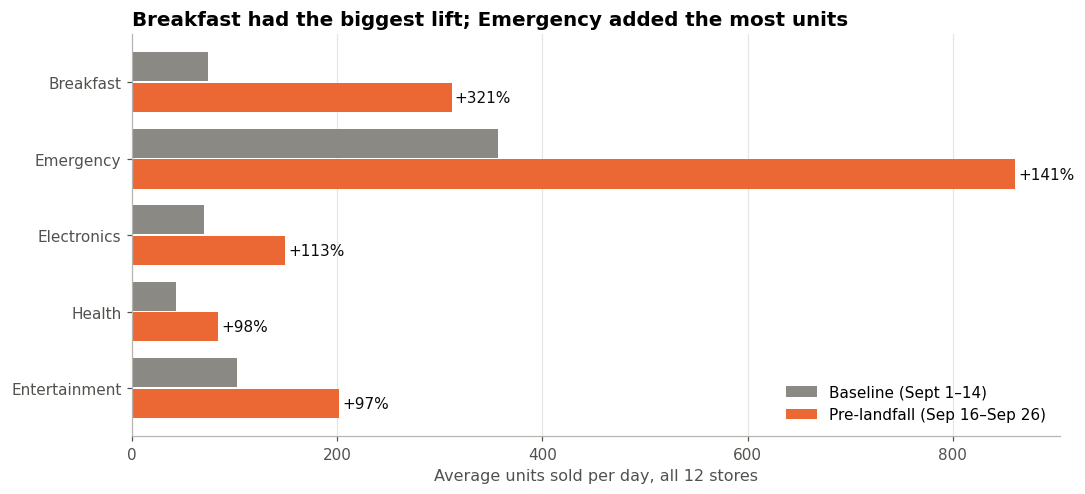

In [17]:
# Chart: baseline vs surge, top 5 categories by lift
plot = cat_lift.loc[top5].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(plot))
ax.barh(y + 0.2, plot["baseline_units_per_day"], height=0.38, color=MUTED, label="Baseline (Sept 1–14)")
ax.barh(y - 0.2, plot["surge_units_per_day"], height=0.38, color=PALETTE[1],
        label=f"Pre-landfall ({SURGE_START:%b %d}–{SURGE_END:%b %d})")
for yi, (_, r) in zip(y, plot.iterrows()):
    ax.text(r["surge_units_per_day"] + 3, yi - 0.2, f"+{r['lift_pct']:.0f}%", va="center", fontsize=10, color="#0b0b0b")
ax.set_yticks(y, plot.index)
ax.set_xlabel("Average units sold per day, all 12 stores")
ax.set_title(f"{top5[0]} had the biggest lift; {cat_lift['extra_units_per_day'].idxmax()} added the most units")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

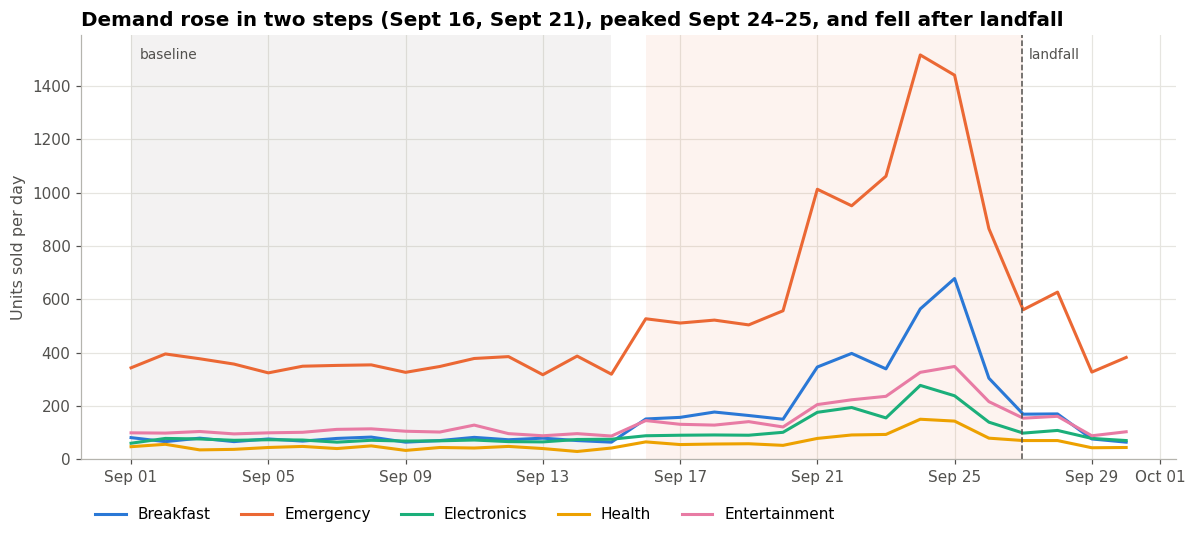

In [18]:
# Chart: daily units for the top 5 categories over the month
daily_cat = dated_sales.groupby(["date", "category"])["quantity"].sum().unstack().fillna(0)
fig, ax = plt.subplots(figsize=(11, 5))
for i, c in enumerate(top5):
    ax.plot(daily_cat.index, daily_cat[c], color=PALETTE[i], label=c)
ax.set_title("Demand rose in two steps (Sept 16, Sept 21), peaked Sept 24–25, and fell after landfall")
ax.set_ylabel("Units sold per day")
ax.set_ylim(0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.axvspan(SURGE_START, SURGE_END + pd.Timedelta(days=1), color=PALETTE[1], alpha=0.08, lw=0)
shade_windows(ax)
ax.legend(loc="upper left", ncol=5, bbox_to_anchor=(0, -0.08))
plt.tight_layout(); plt.show()

In [19]:
q1 = cat_lift
print(f"Q1 numbers: surge window {SURGE_START:%b %d}–{SURGE_END:%b %d}; total units/day "
      f"{base.mean():.0f} -> {daily_units[SURGE_START:SURGE_END].mean():.0f} "
      f"(+{100 * (daily_units[SURGE_START:SURGE_END].mean() / base.mean() - 1):.0f}%)")
for c, r in q1.head(5).iterrows():
    print(f"  {c:<14} {r.baseline_units_per_day:>6.1f} -> {r.surge_units_per_day:>6.1f} units/day  (+{r.lift_pct:.0f}%)")
print(f"Smallest lift: {q1.index[-1]} (+{q1['lift_pct'].iloc[-1]:.0f}%)")

Q1 numbers: surge window Sep 16–Sep 26; total units/day 1109 -> 2347 (+112%)
  Breakfast        73.9 ->  311.5 units/day  (+321%)
  Emergency       356.6 ->  860.9 units/day  (+141%)
  Electronics      69.9 ->  149.0 units/day  (+113%)
  Health           42.4 ->   83.7 units/day  (+98%)
  Entertainment   102.6 ->  201.8 units/day  (+97%)
Smallest lift: Snacks (+17%)


### Q1 finding
*Every number here is printed by the cells above.*

**Baseline and window.** Sept 1–14 is flat: about 1,109 units/day with a coefficient of variation of 2.9%. Every day from
**Sept 16 through landfall on Sept 26** clears the mean + 3 SD threshold of 1,206 units/day, so that is our surge window.
Over it, total volume averaged **2,347 units/day (+112%)**. The window has clear phases:
- **Early build (Sept 16–20):** +38%. This is a week before the first NHC advisory.
- **Second step (Sept 21–23):** +144%.
- **Peak (Sept 24–25):** +254%, about **3.5× normal**.
- **Landfall day (Sept 26):** volume fell back to +101%.
- **Sept 29:** back to normal.

**Top 5 categories by lift (Sept 16–26 vs. baseline):**
1. **Breakfast +321%.** This is entirely Strawberry Pop-Tarts. At the Sept 24–25 peak it hit **8.4× normal (+740%)**, which echoes the case's "sevenfold".
2. **Emergency +141%.** It is the biggest by volume, adding **~504 extra units/day**: water, batteries, flashlights, candles and tarps. At the peak it ran at 4.2× normal.
3. **Electronics +113%.** Portable chargers and streaming sticks.
4. **Health +98%.** First-aid kits.
5. **Entertainment +97%.** Monopoly and playing cards. This is the board-game signal Q5 has to test.

Snacks barely moved (+17%), which is a useful control: not *everything* goes up.

**Is this robust?** Breakfast, Emergency and Electronics stay at #1–3 under all three baselines we tried. Health,
Entertainment and Alcohol trade places for #4–5, separated by only a few points, so treat 4–6 as a tie. The 3.5% of
sales with no timestamp fall across categories within 2 points of each category's share of all sales, so leaving them
out does not bias the ranking.

**For leadership:** the buying window opens **about 10 days before landfall** and peaks **two days before** it.
Emergency needs the most trucks. Pop-Tarts needs the biggest *relative* increase, about 8× at the peak.

## 5. Q2: SKU consolidation
**Question.** How much does SKU fragmentation hide, and what does the picture look like once SKUs are consolidated?

The mapping table (`SKU_MAP`, section 2.1) maps 45 SKUs to 20 products. Below: the mapping, then before vs. after.

In [20]:
SKU_MAP.groupby(["product_id", "product", "category"])["sku"].agg(lambda s: ", ".join(s)).reset_index().rename(columns={"sku": "SKUs merged"})

,product_id,product,category,SKUs merged
0,P01,Pop-Tarts Strawberry,Breakfast,"POPTART-STRAW, PT-12, PT_STRAWBERRY, SKU#459812"
1,P02,Bottled Water 24-Pack,Emergency,"WATER24PK, WTR-24, WTR_24PK"
2,P03,AA Batteries 4-Pack,Emergency,"BAT-AA4, BATT-100, BATT_AA_4PK"
3,P04,LED Flashlight,Emergency,"FLASH-01, LED-FLASH"
4,P05,Light Beer 24-Pack,Alcohol,"BEER-24, LTBEER24"
5,P06,Monopoly Board Game,Entertainment,"BG-MONO, GAME-MONO, MONOPOLY-01"
6,P07,Playing Cards,Entertainment,"CARDS-01, PLAYCARD-STD"
7,P08,Roku Streaming Stick,Electronics,"ROKU-STD, STREAM-01"
8,P09,Canned Soup,Grocery,"CNSOUP-01, SOUP-CAN"
9,P10,White Bread,Grocery,"BREAD-WH, WHITEBREAD"


In [21]:
# Catalog conflicts inside the same product: these are why the catalog can't be trusted for cost or pack size
conf = catalog.groupby("product").agg(
    skus=("sku", "count"),
    names=("product_name", "nunique"),
    raw_categories=("category_raw", "nunique"),
    unit_cost_min=("unit_cost", "min"), unit_cost_max=("unit_cost", "max"),
    package_sizes=("package_size", lambda s: ", ".join(sorted(s.dropna().unique()))),
    suppliers=("supplier", lambda s: ", ".join(sorted(s.dropna().unique()))),
)
conf["cost_spread_pct"] = (100 * (conf["unit_cost_max"] / conf["unit_cost_min"] - 1)).round(0)
conf.sort_values("skus", ascending=False).head(8)

,skus,names,raw_categories,unit_cost_min,unit_cost_max,package_sizes,suppliers,cost_spread_pct
product,,,,,,,,
Pop-Tarts Strawberry,4,3,3,1.93,2.26,"4 pack, 4-pack, 4pk, 6 pack","Campbell's, Johnson & Johnson, Roku Inc, Sara Lee",17.0
AA Batteries 4-Pack,3,2,2,3.71,4.16,"24 pack, 4pk, 6 pack","3M Company, Anheuser-Busch, Kimberly-Clark",12.0
Monopoly Board Game,3,2,2,9.96,12.51,"1pk, 24-pack","Campbell's, Georgia-Pacific, Kimberly-Clark",26.0
Bottled Water 24-Pack,3,3,2,2.08,2.64,"1 pack, 24 pack","Frito-Lay, Sara Lee",27.0
Chips Variety Pack,2,2,2,4.03,4.11,"4-pack, single","Frito-Lay, Generic Supplier",2.0
Canned Soup,2,2,2,1.19,1.23,single,"Generic Supplier, J.M. Smucker",3.0
First Aid Kit,2,2,1,6.90,7.85,4 pack,"Anheuser-Busch, J.M. Smucker",14.0
Diapers Size 3,2,2,2,13.59,14.40,"6 pack, single","Generic Supplier, Procter & Gamble",6.0


In [22]:
surge_sales = dated_sales[(dated_sales["date"] >= SURGE_START) & (dated_sales["date"] <= SURGE_END)]
n_surge_days = (SURGE_END - SURGE_START).days + 1

before = (surge_sales.groupby(["sku", "product_name"])["quantity"].sum() / n_surge_days).rename("units_per_day").reset_index()
before["rank"] = before["units_per_day"].rank(ascending=False, method="min").astype(int)
after_ = (surge_sales.groupby("product_name")["quantity"].sum() / n_surge_days).rename("units_per_day").reset_index()
after_["rank"] = after_["units_per_day"].rank(ascending=False, method="min").astype(int)

pt = "Pop-Tarts Strawberry"
pt_before = before[before["product_name"] == pt].sort_values("rank")
pt_after = after_[after_["product_name"] == pt].iloc[0]
summary = pd.DataFrame({
    "before (by SKU)": [before["sku"].nunique(), int(pt_before["rank"].min()), round(pt_before["units_per_day"].max(), 1),
                        f"{len(pt_before)} separate lines"],
    "after (by product)": [after_["product_name"].nunique(), int(pt_after["rank"]), round(pt_after["units_per_day"], 1),
                           "1 line"],
}, index=["items a buyer has to scan", "best Pop-Tarts rank (surge window)", "Pop-Tarts units/day (largest line)",
          "how Pop-Tarts shows up"])
summary

,before (by SKU),after (by product)
items a buyer has to scan,45,20
best Pop-Tarts rank (surge window),4,1
Pop-Tarts units/day (largest line),81.5,311.5
how Pop-Tarts shows up,4 separate lines,1 line


In [23]:
# Lift before and after: does fragmentation change the % story, the volume story, or both?
sku_lift = lift_table(dated_sales, "sku")
prod_lift = lift_table(dated_sales, "product_name")
pt_skus = SKU_MAP.loc[SKU_MAP["product"] == pt, "sku"]
cmp = pd.concat([sku_lift.loc[pt_skus].assign(level="SKU"),
                 prod_lift.loc[[pt]].assign(level="Product")])
cmp

,baseline_units_per_day,surge_units_per_day,extra_units_per_day,lift_pct,level
POPTART-STRAW,17.9,76.9,59.0,329.0,SKU
PT-12,20.6,81.5,60.9,295.0,SKU
PT_STRAWBERRY,18.4,76.9,58.5,317.3,SKU
SKU#459812,16.9,76.2,59.3,350.0,SKU
Pop-Tarts Strawberry,73.9,311.5,237.6,321.4,Product


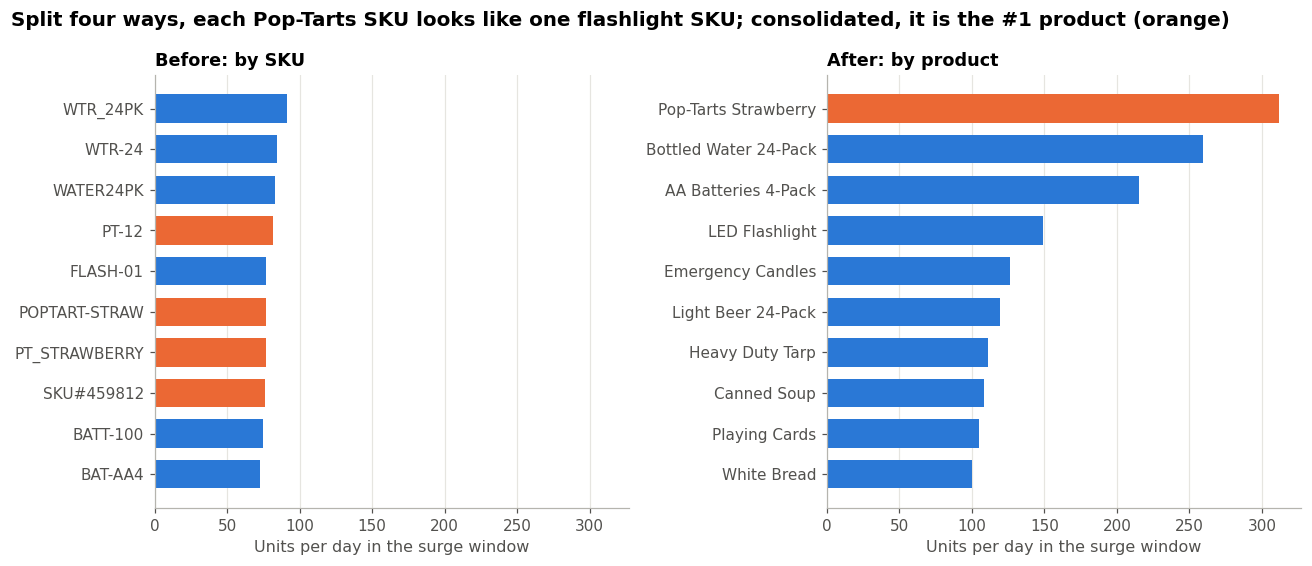

In [24]:
# Chart: top 10 lines in the surge window, by SKU vs. by product
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True)
b10 = before.nlargest(10, "units_per_day").iloc[::-1]
a10 = after_.nlargest(10, "units_per_day").iloc[::-1]
for ax, d, label, title in [(axes[0], b10, "sku", "Before: by SKU"), (axes[1], a10, "product_name", "After: by product")]:
    colors = [PALETTE[1] if (n == pt) else PALETTE[0] for n in d["product_name"]]
    ax.barh(d[label], d["units_per_day"], color=colors, height=0.7)
    ax.set_title(title, fontsize=11.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Units per day in the surge window")
fig.suptitle(f"Split four ways, each Pop-Tarts SKU looks like one flashlight SKU; consolidated, it is the #{int(pt_after['rank'])} product (orange)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

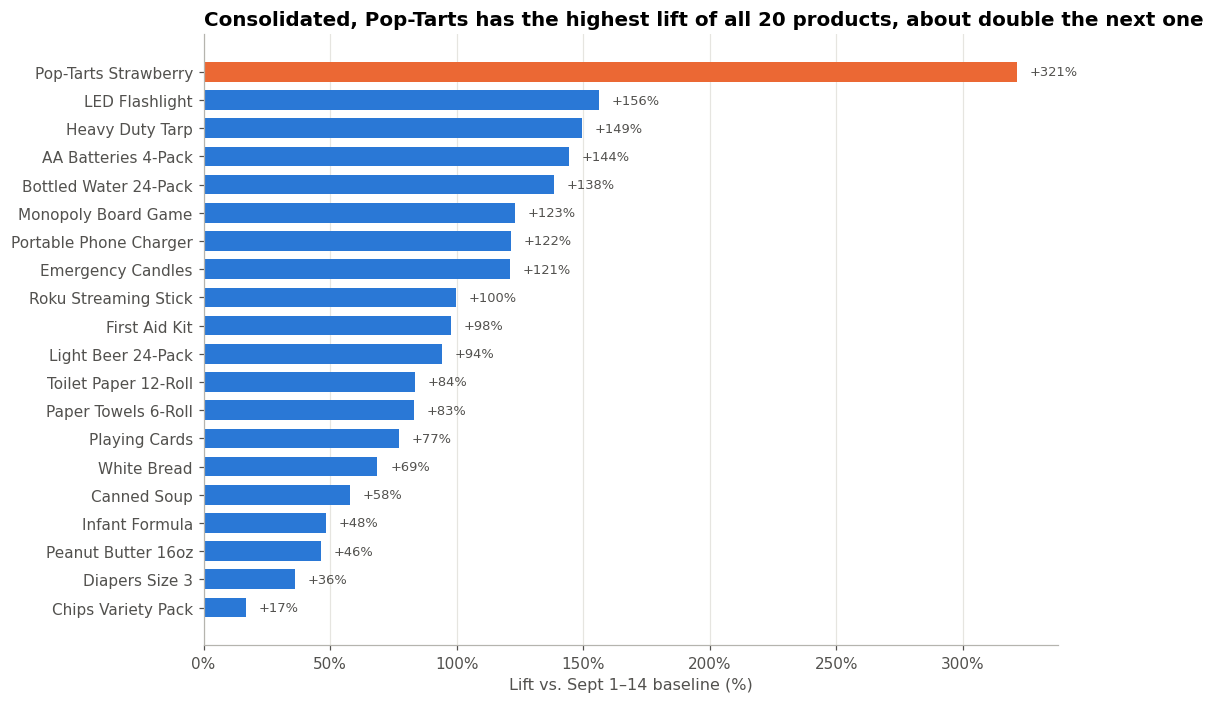

In [25]:
# Chart: product-level lift after consolidation, all 20 products
pl = prod_lift.sort_values("lift_pct")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(pl.index, pl["lift_pct"], color=[PALETTE[1] if p == pt else PALETTE[0] for p in pl.index], height=0.7)
for i, (p, v) in enumerate(pl["lift_pct"].items()):
    ax.text(v + 5, i, f"+{v:.0f}%", va="center", fontsize=8.5, color="#52514e")
ax.set_title("Consolidated, Pop-Tarts has the highest lift of all 20 products, about double the next one")
ax.set_xlabel("Lift vs. Sept 1–14 baseline (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [26]:
pt_lift = prod_lift.loc[pt, "lift_pct"]
print(f"Pop-Tarts: {len(pt_skus)} SKUs -> 1 product | product lift +{pt_lift:.0f}% | "
      f"rank by surge volume {int(pt_before['rank'].min())} (best single SKU) -> {int(pt_after['rank'])} (consolidated)")
print("Product lift ranking (top 6):", prod_lift.head(6)["lift_pct"].to_dict())

Pop-Tarts: 4 SKUs -> 1 product | product lift +321% | rank by surge volume 4 (best single SKU) -> 1 (consolidated)
Product lift ranking (top 6): {'Pop-Tarts Strawberry': 321.4, 'LED Flashlight': 156.1, 'Heavy Duty Tarp': 149.4, 'AA Batteries 4-Pack': 144.5, 'Bottled Water 24-Pack': 138.5, 'Monopoly Board Game': 123.1}


### Q2 finding
*Every number here is printed by the cells above.*

**The mapping.** We consolidated **45 SKUs into 20 products**, linking SKUs that cashiers sold under the same product name.
- Strawberry Pop-Tarts was split across **four** SKUs: `PT-12`, `SKU#459812`, `POPTART-STRAW` and `PT_STRAWBERRY`.
- Bottled water, AA batteries and Monopoly were each split across **three**.
- Every other product was split across two.

**Before vs. after (Sept 16–26 surge window).**
- **By SKU:** the top three lines are all bottled water (~84–92 units/day each). Each Pop-Tarts SKU sells ~76–82
  units/day, about the same as a single flashlight SKU, and they sit at ranks 4, 5, 5 and 8.
- **By product:** Pop-Tarts is the **#1 product at 312 units/day**, ahead of water (259) and batteries (215).

**What changes and what doesn't.** Consolidation leaves the *percentage* lift almost unchanged: each Pop-Tarts SKU shows
+295% to +350%, and the product shows +321%. What it fixes is **size and rank**. A buyer reading a SKU report sees four
ordinary lines, and water at the top. The real answer is that Pop-Tarts is the single biggest-moving product before the
storm, and its lift is the highest of all 20 products, roughly double the next one (LED flashlights, +156%).

**The catalog can't be trusted for anything but the SKU list.** Within the same product:
- Unit costs differ by up to **27%** (water) and 26% (Monopoly).
- Package sizes contradict each other: water is listed as "1 pack" and "24 pack", batteries as "4pk" and "24 pack".
- Suppliers are implausible: Pop-Tarts is listed under Roku Inc and Johnson & Johnson.

That's why we consolidated on POS evidence, not catalog attributes. Any cost or margin analysis should wait for a catalog fix.

**Recommendation:** forecast and replenish at the **product** level, and keep the SKU→product map (`SKU_MAP`) as a
maintained ETL step. Q5 needs the same consolidation, because Monopoly's three SKUs and two card SKUs are exactly
the "mis-coded bundle" risk the Finance VP raised.

## 6. Q3: Weather correlation and lag
**Question.** How closely do sales track the weather, and does buying *lead* the weather?

We use the checked store × day table from section 3.1 (360 rows). The weather variables are daily **max wind gust (mph)**,
**total precipitation (in)** and **minimum sea-level pressure (hPa)**. The pressure drop is the cleanest storm-proximity
signal. Two views:
1. **Same-day correlation**, pooled across store-days and statewide (daily averages across the 12 stores).
2. **Lag analysis:** correlate sales on day *t* with weather on day *t + k*. A peak at **k > 0** means sales
   **lead** the weather: people buy *before* the storm arrives.

In [27]:
WX = ["max_gust_mph", "precip_in", "min_pressure_hpa"]
statewide = joined.groupby("date").agg(units=("units", "sum"), **{c: (c, "mean") for c in WX})

same_day = pd.DataFrame({
    "pooled r (360 store-days)": [joined["units"].corr(joined[c]) for c in WX],
    "pooled Spearman": [joined["units"].corr(joined[c], method="spearman") for c in WX],
    "statewide r (30 days)": [statewide["units"].corr(statewide[c]) for c in WX],
}, index=WX).round(2)
same_day

,pooled r (360 store-days),pooled Spearman,statewide r (30 days)
max_gust_mph,0.18,0.19,0.22
precip_in,-0.17,-0.26,-0.32
min_pressure_hpa,-0.21,-0.39,-0.24


In [28]:
LAGS = range(-5, 6)
def lag_corr(df, var, lags=LAGS):
    """corr(units_t, weather_{t+k}) inside each store, then averaged across stores."""
    out = {}
    for k in lags:
        rs = []
        for _, g in df.sort_values("date").groupby("store_id"):
            rs.append(g["units"].corr(g[var].shift(-k)))
        out[k] = np.nanmean(rs)
    return pd.Series(out, name=var)

lags = pd.concat([lag_corr(joined, v) for v in WX], axis=1).round(2)
lags.index.name = "k (weather is k days after sales)"
best = {v: (lags[v].abs().idxmax(), lags[v].loc[lags[v].abs().idxmax()]) for v in WX}
print("Strongest lag per variable:", {v: f"k={k:+d}, r={r:+.2f}" for v, (k, r) in best.items()})
lags

Strongest lag per variable: {'max_gust_mph': 'k=+2, r=+0.71', 'precip_in': 'k=-4, r=-0.36', 'min_pressure_hpa': 'k=+2, r=-0.76'}


,max_gust_mph,precip_in,min_pressure_hpa
k (weather is k days after sales),,,
-5,-0.24,-0.28,-0.46
-4,-0.21,-0.36,-0.09
-3,-0.22,-0.36,0.01
-2,-0.13,-0.35,-0.09
-1,0.00,-0.34,-0.15
0,0.18,-0.19,-0.25
1,0.50,-0.01,-0.57
2,0.71,0.02,-0.76
3,0.57,0.01,-0.57


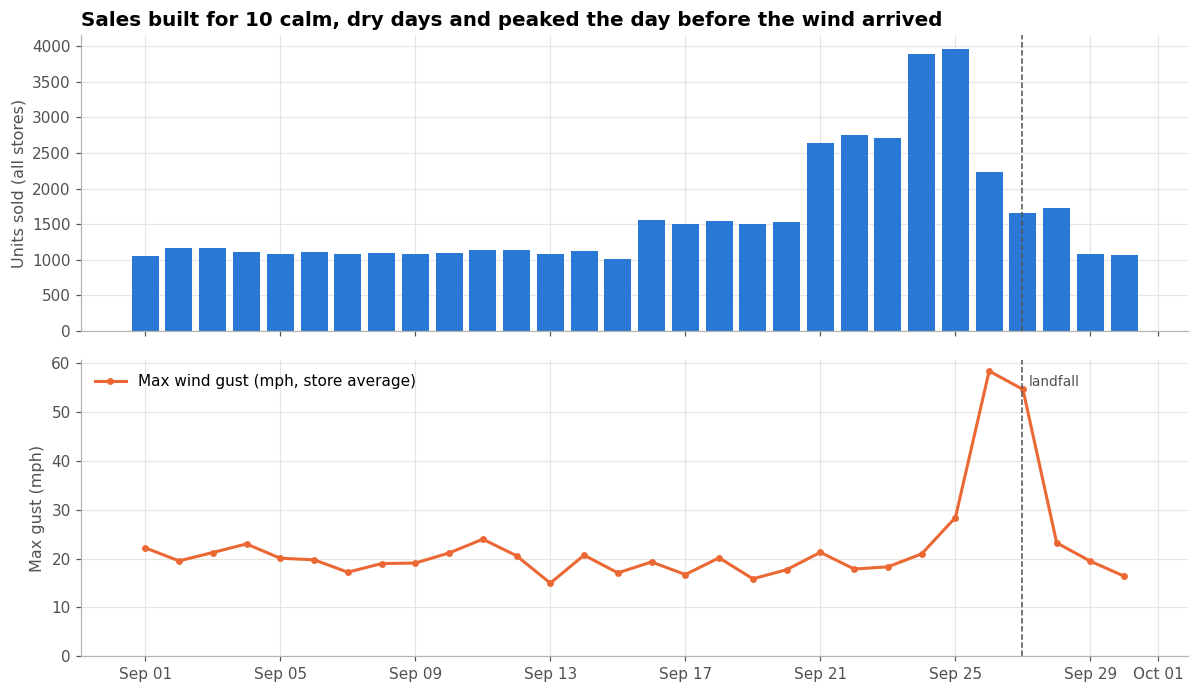

In [29]:
# Chart: statewide sales and weather on two stacked panels with a shared date axis (no dual axis)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
a1.bar(statewide.index, statewide["units"], color=PALETTE[0], width=0.8)
a1.set_ylabel("Units sold (all stores)")
a1.set_title("Sales built for 10 calm, dry days and peaked the day before the wind arrived")
a2.plot(statewide.index, statewide["max_gust_mph"], color=PALETTE[1], marker="o", ms=3.5, label="Max wind gust (mph, store average)")
a2.set_ylabel("Max gust (mph)")
a2.set_ylim(0)
for ax in (a1, a2):
    ax.axvline(LANDFALL_DATE + pd.Timedelta(hours=23), color="#52514e", ls="--", lw=1)
a2.text(LANDFALL_DATE + pd.Timedelta(hours=28), a2.get_ylim()[1] * 0.95, "landfall", ha="left", va="top", fontsize=9, color="#52514e")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
a2.legend(loc="upper left")
plt.tight_layout(); plt.show()

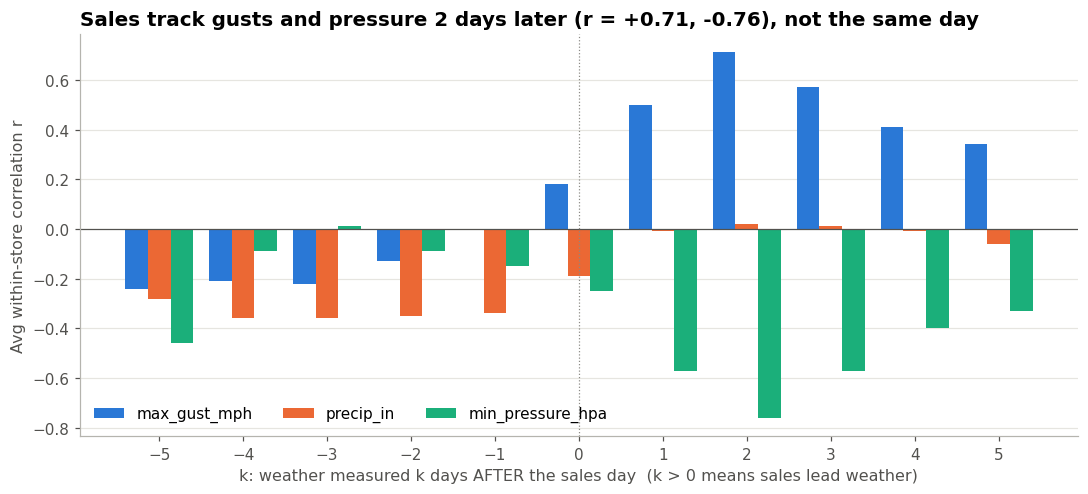

In [30]:
# Chart: lag correlation profile
fig, ax = plt.subplots(figsize=(10, 4.6))
w = 0.27
for i, v in enumerate(WX):
    ax.bar(np.array(list(LAGS)) + (i - 1) * w, lags[v], width=w, color=PALETTE[i], label=v)
ax.axhline(0, color="#52514e", lw=0.8)
ax.axvline(0, color=MUTED, lw=0.8, ls=":")
ax.set_xticks(list(LAGS))
ax.set_xlabel("k: weather measured k days AFTER the sales day  (k > 0 means sales lead weather)")
ax.set_ylabel("Avg within-store correlation r")
k_g, r_g = best["max_gust_mph"]; k_p, r_p = best["min_pressure_hpa"]
ax.set_title(f"Sales track gusts and pressure {k_g} days later (r = {r_g:+.2f}, {r_p:+.2f}), not the same day")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncol=3)
plt.tight_layout(); plt.show()

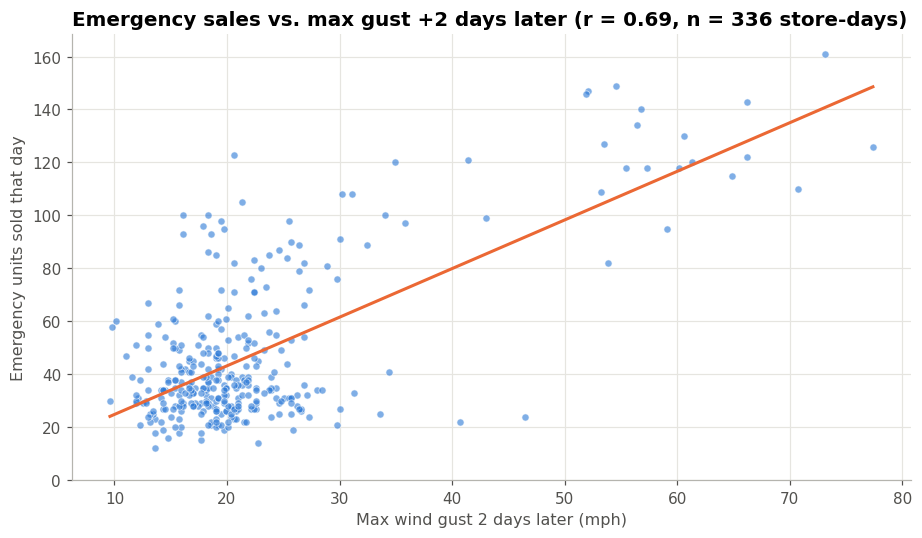

In [31]:
# Chart: Emergency units vs. max gust k* days later, every store-day
k_star, r_star = best["max_gust_mph"]
em = (dated_sales[dated_sales["category"] == "Emergency"].groupby(["store_id", "date"])["quantity"].sum()
      .rename("emergency_units").reset_index())
sc = joined.merge(em, on=["store_id", "date"], how="left").fillna({"emergency_units": 0}).sort_values(["store_id", "date"])
sc["gust_future"] = sc.groupby("store_id")["max_gust_mph"].shift(-k_star)
sc = sc.dropna(subset=["gust_future"])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(sc["gust_future"], sc["emergency_units"], s=22, color=PALETTE[0], alpha=0.6, edgecolor="white", linewidth=0.6)
m, b = np.polyfit(sc["gust_future"], sc["emergency_units"], 1)
xs = np.linspace(sc["gust_future"].min(), sc["gust_future"].max(), 50)
ax.plot(xs, m * xs + b, color=PALETTE[1], lw=2)
r_em = sc["emergency_units"].corr(sc["gust_future"])
ax.set_title(f"Emergency sales vs. max gust {k_star:+d} days later (r = {r_em:.2f}, n = {len(sc)} store-days)")
ax.set_xlabel(f"Max wind gust {k_star} days later (mph)")
ax.set_ylabel("Emergency units sold that day")
ax.set_ylim(0)
plt.tight_layout(); plt.show()

In [32]:
peak_sales_day = statewide["units"].idxmax()
peak_gust_day = statewide["max_gust_mph"].idxmax()
low_pressure_day = statewide["min_pressure_hpa"].idxmin()
print(f"Statewide peak sales day: {peak_sales_day:%b %d} | peak gust day: {peak_gust_day:%b %d} | lowest pressure day: {low_pressure_day:%b %d}")
print(f"Sales lead the gust peak by {(peak_gust_day - peak_sales_day).days} days")
print("Same-day r:", same_day['pooled r (360 store-days)'].to_dict())
print("Best lag:", {v: f"k={k:+d}, r={r:+.2f}" for v, (k, r) in best.items()})
top_gust = joined.loc[joined.groupby("store_id")["max_gust_mph"].idxmax(), ["store_id", "date", "max_gust_mph"]].merge(
    stores[["store_id", "city"]]).sort_values("max_gust_mph", ascending=False)
top_gust

Statewide peak sales day: Sep 25 | peak gust day: Sep 26 | lowest pressure day: Sep 26
Sales lead the gust peak by 1 days
Same-day r: {'max_gust_mph': 0.18, 'precip_in': -0.17, 'min_pressure_hpa': -0.21}
Best lag: {'max_gust_mph': 'k=+2, r=+0.71', 'precip_in': 'k=-4, r=-0.36', 'min_pressure_hpa': 'k=+2, r=-0.76'}


,store_id,date,max_gust_mph,city
8,FL-445,2024-09-26,77.4,St. Petersburg
1,FL-105,2024-09-26,73.1,Tampa
0,FL-078,2024-09-27,70.7,Gainesville
7,FL-412,2024-09-27,66.2,Jacksonville
10,FL-619,2024-09-27,60.6,Tallahassee
5,FL-302,2024-09-26,60.2,Lakeland
9,FL-501,2024-09-26,59.1,Fort Myers
3,FL-239,2024-09-26,57.3,Orlando
4,FL-287,2024-09-26,56.8,Kissimmee
2,FL-156,2024-09-27,55.5,Daytona Beach


### Q3 finding
*Every number here is printed by the cells above.*

**Same-day weather barely explains sales.** Across 360 store-days, units correlate only weakly with that day's max gust (r = 0.18), rain (r = −0.17) and pressure (r = −0.21). The reason shows up in the statewide table: the surge days **Sept 21–24 were calm and dry**. Average max gusts were 18–21 mph, the same as the baseline. Rain was 0.01–0.03 in, and pressure was a normal ~1,011 hPa.

**Weather two days ahead explains sales well.** Lining each store's sales up against its own weather **k days later** gives a clear peak at **k = +2**:
- **Max gust:** r = **+0.71**.
- **Minimum pressure:** r = **−0.76**. It's negative because lower pressure means a closer storm.
- **Emergency category alone:** r = 0.69 against gusts two days later (336 store-days).
- **Rain:** no relationship at any lead time (|r| ≤ 0.06 for k ≥ 1).

**The timeline.**
- **Sales:** peaked on **Sept 25**.
- **Storm arrival (Sept 26):** store-average max gust 58 mph, pressure down to 996 hPa, and the most rain of the month (0.88 in).
- **Strongest gusts:** St. Petersburg 77 mph and Tampa 73 mph on Sept 26, then Gainesville 71 mph on Sept 27.
- **Sales afterwards:** fell as soon as the wind arrived.

**A useful check: Pensacola.** Its windiest day of the month was **Sept 12** (47 mph, the day after Hurricane Francine hit Louisiana). Its sales that day were slightly *below* normal: 80 units vs. ~95. Wind with no Florida storm forecast doesn't move buying.

**What it means:** customers **buy on the forecast, not on the weather**. Sales lead the storm, so a weather feed is useful as a *leading* signal, read 2+ days out. It is useless as a same-day trigger.

**Caveats we checked.**
- **Timezones:** the weather came in GMT and was converted per store. For example, 02:00 GMT on Sept 27 is 10 pm Sept 26 in Orlando and 9 pm in Pensacola, which is on Central time.
- **The join:** exactly 360 rows with no nulls, and it preserves every dated unit.
- **Sample size:** this is one storm over 30 days, so these r values are descriptive, not a forecast model.
- **Causation:** sales and future weather both respond to the same storm, so the lag is evidence of forecast-driven buying, not proof of cause.

**For leadership:** trigger replenishment off the **forecast track** (expected gusts and pressure drop), at least 2 days out and ideally from the first outlook. Same-day weather alerts arrive after demand has already peaked.

## 7. Q4: Stores and geography
**Question.** Did every store surge the same way, and does geography explain the difference? Specifically: distance from
Helene's landfall, and how hard the wind actually hit each store.

**Inputs.** The store file joins cleanly to every transaction: `clean_store_id()` collapsed 60 spellings to 12 ids, and the
join check in section 1 found no orphans. Landfall per the NHC: **30.0°N, 83.7°W**, just east of the mouth of the Aucilla
River, 11:10 pm EDT Sept 26. Distances are straight-line (haversine), in miles. Each store's storm exposure is its max gust
and lowest pressure between **Sept 25 and 28**, from the weather join in section 3.

In [33]:
LANDFALL_LAT, LANDFALL_LON = 30.0, -83.7     # NHC update, 11:10 pm EDT Sept 26, 2024

def haversine_mi(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))

PEAK = (pd.Timestamp("2024-09-24"), pd.Timestamp("2024-09-25"))
storm = joined[joined["date"].between("2024-09-25", "2024-09-28")].groupby("store_id").agg(
    storm_gust_mph=("max_gust_mph", "max"), storm_min_pressure=("min_pressure_hpa", "min"))

def surge_start(series):
    """First day after the baseline when a store's units clear its own baseline mean + 3 SD."""
    b = series[BASELINE_START:BASELINE_END]
    c = series[SURGE_SEARCH_START:LANDFALL_DATE]
    return c[c > b.mean() + 3 * b.std()].index.min()

store_daily = dated_sales.groupby(["date", "store_id"])["quantity"].sum().unstack()
q4 = pd.DataFrame({
    "baseline_per_day": window_rate(dated_sales, BASELINE_START, BASELINE_END, "store_id"),
    "surge_per_day": window_rate(dated_sales, SURGE_START, SURGE_END, "store_id"),
    "peak_per_day": window_rate(dated_sales, *PEAK, "store_id"),
    "surge_start": store_daily.apply(surge_start),
})
q4["lift_pct"] = 100 * (q4["surge_per_day"] / q4["baseline_per_day"] - 1)
q4["peak_multiple"] = q4["peak_per_day"] / q4["baseline_per_day"]
q4 = q4.join(stores.set_index("store_id")[["city", "region", "latitude", "longitude"]]).join(storm)
q4["miles_from_landfall"] = haversine_mi(q4["latitude"], q4["longitude"], LANDFALL_LAT, LANDFALL_LON)
q4 = q4.sort_values("lift_pct", ascending=False)
q4[["city", "region", "baseline_per_day", "surge_per_day", "lift_pct", "peak_multiple", "miles_from_landfall",
    "storm_gust_mph", "storm_min_pressure"]].round(1).assign(surge_start=q4["surge_start"].dt.strftime("%b %d"))

,city,region,baseline_per_day,surge_per_day,lift_pct,peak_multiple,miles_from_landfall,storm_gust_mph,storm_min_pressure,surge_start
store_id,,,,,,,,,,
FL-330,Miami,South,86.9,209.0,140.4,3.7,362.8,53.5,1005.6,Sep 16
FL-619,Tallahassee,Panhandle,86.4,197.1,128.2,3.7,46.0,60.6,977.3,Sep 16
FL-105,Tampa,West,91.8,198.4,116.1,3.8,160.3,73.1,993.5,Sep 16
FL-287,Kissimmee,Central,91.0,193.6,112.8,3.4,181.8,56.8,998.8,Sep 18
FL-302,Lakeland,Central,98.0,208.0,112.2,3.9,171.8,60.2,997.0,Sep 16
FL-710,Pensacola,Panhandle,93.3,195.6,109.7,3.6,212.0,34.9,997.9,Sep 16
FL-412,Jacksonville,North,91.1,190.5,109.0,3.7,124.3,66.2,992.5,Sep 16
FL-445,St. Petersburg,West,95.9,199.9,108.4,3.6,167.0,77.4,992.7,Sep 17
FL-156,Daytona Beach,East,95.2,194.8,104.6,3.4,169.8,55.5,998.5,Sep 17


In [34]:
# Does geography explain the differences? 12 stores, so these are descriptive, not tests.
geo = pd.DataFrame({
    "r with lift_pct": [q4["lift_pct"].corr(q4[c]) for c in ["miles_from_landfall", "storm_gust_mph", "storm_min_pressure"]],
    "Spearman with lift_pct": [q4["lift_pct"].corr(q4[c], method="spearman") for c in ["miles_from_landfall", "storm_gust_mph", "storm_min_pressure"]],
    "r with peak_multiple": [q4["peak_multiple"].corr(q4[c]) for c in ["miles_from_landfall", "storm_gust_mph", "storm_min_pressure"]],
}, index=["miles_from_landfall", "storm_gust_mph", "storm_min_pressure"]).round(2)
print(f"Lift range: {q4['lift_pct'].min():.0f}% ({q4['lift_pct'].idxmin()} {q4.loc[q4['lift_pct'].idxmin(), 'city']}) to "
      f"{q4['lift_pct'].max():.0f}% ({q4['lift_pct'].idxmax()} {q4.loc[q4['lift_pct'].idxmax(), 'city']}); "
      f"coefficient of variation across stores {q4['lift_pct'].std() / q4['lift_pct'].mean():.0%}")
print(f"Peak multiple range: {q4['peak_multiple'].min():.2f}x to {q4['peak_multiple'].max():.2f}x")
print("Surge start dates:", q4["surge_start"].dt.strftime("%b %d").value_counts().to_dict())
geo

Lift range: 95% (FL-239 Orlando) to 140% (FL-330 Miami); coefficient of variation across stores 11%
Peak multiple range: 3.05x to 3.86x
Surge start dates: {'Sep 16': 9, 'Sep 17': 2, 'Sep 18': 1}


,r with lift_pct,Spearman with lift_pct,r with peak_multiple
miles_from_landfall,0.31,-0.01,-0.03
storm_gust_mph,-0.10,-0.09,0.14
storm_min_pressure,-0.07,-0.03,-0.21


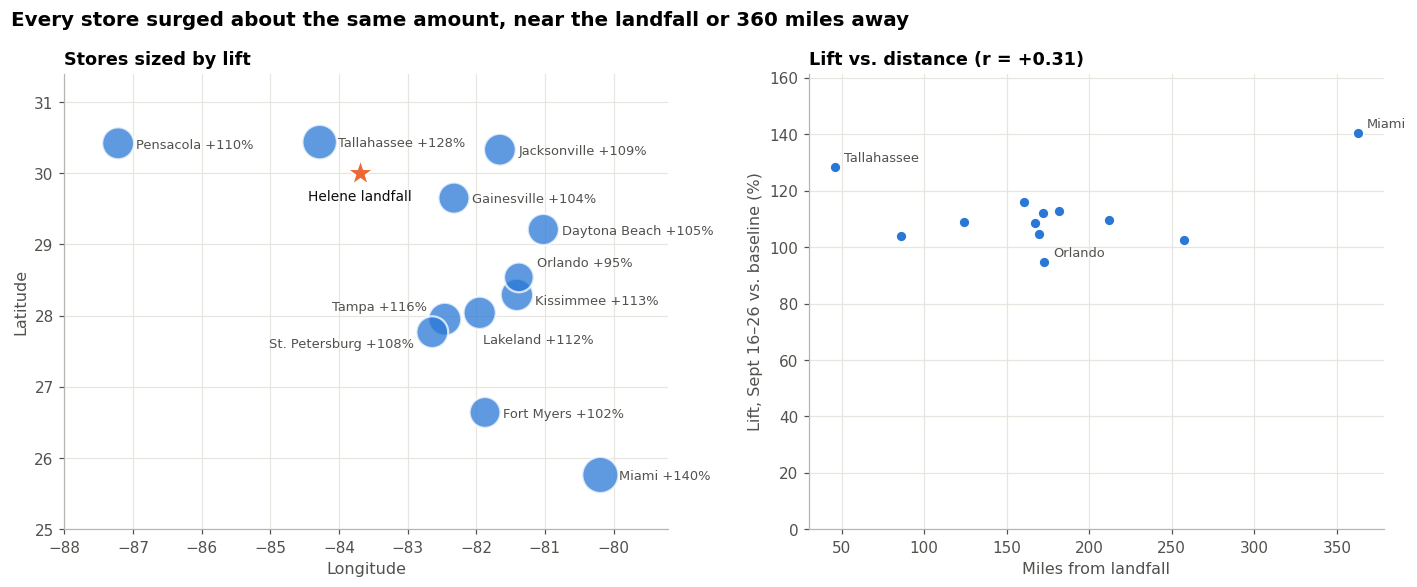

In [35]:
# Chart: where the stores are vs. landfall, and lift vs. distance
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.05, 1]})
a1.scatter(q4["longitude"], q4["latitude"], s=q4["lift_pct"] * 4, color=PALETTE[0], alpha=0.75, edgecolor="white", linewidth=1.5)
# label offsets (points) so the central-Florida cluster doesn't overlap
OFFSETS = {"FL-105": (-12, 6, "right"), "FL-445": (-12, -10, "right"), "FL-302": (2, -20, "left"),
           "FL-287": (12, -6, "left"), "FL-239": (12, 7, "left")}
for sid, r in q4.iterrows():
    dx, dy, ha = OFFSETS.get(sid, (12, -3, "left"))
    a1.annotate(f"{r['city']} +{r['lift_pct']:.0f}%", (r["longitude"], r["latitude"]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, fontsize=8.5, color="#52514e")
a1.scatter([LANDFALL_LON], [LANDFALL_LAT], marker="*", s=320, color=PALETTE[1], edgecolor="white", linewidth=1, zorder=5)
a1.annotate("Helene landfall", (LANDFALL_LON, LANDFALL_LAT), xytext=(0, -18), textcoords="offset points",
            ha="center", fontsize=9, color="#0b0b0b")
a1.set_xlim(-88, -79.2); a1.set_ylim(25, 31.4)
a1.set_xlabel("Longitude"); a1.set_ylabel("Latitude")
a1.set_title("Stores sized by lift", fontsize=11.5)
a2.scatter(q4["miles_from_landfall"], q4["lift_pct"], s=50, color=PALETTE[0], edgecolor="white", linewidth=1)
for sid, r in q4.iterrows():   # label the ends of the range; the middle cluster is labeled on the map
    if sid in (q4["lift_pct"].idxmax(), q4["lift_pct"].idxmin(), q4["miles_from_landfall"].idxmin(), q4["miles_from_landfall"].idxmax()):
        a2.annotate(r["city"], (r["miles_from_landfall"], r["lift_pct"]), xytext=(6, 4), textcoords="offset points",
                    fontsize=8.5, color="#52514e")
a2.set_xlabel("Miles from landfall")
a2.set_ylabel("Lift, Sept 16–26 vs. baseline (%)")
a2.set_ylim(0, q4["lift_pct"].max() * 1.15)
a2.set_title(f"Lift vs. distance (r = {geo.loc['miles_from_landfall', 'r with lift_pct']:+.2f})", fontsize=11.5)
fig.suptitle("Every store surged about the same amount, near the landfall or 360 miles away",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

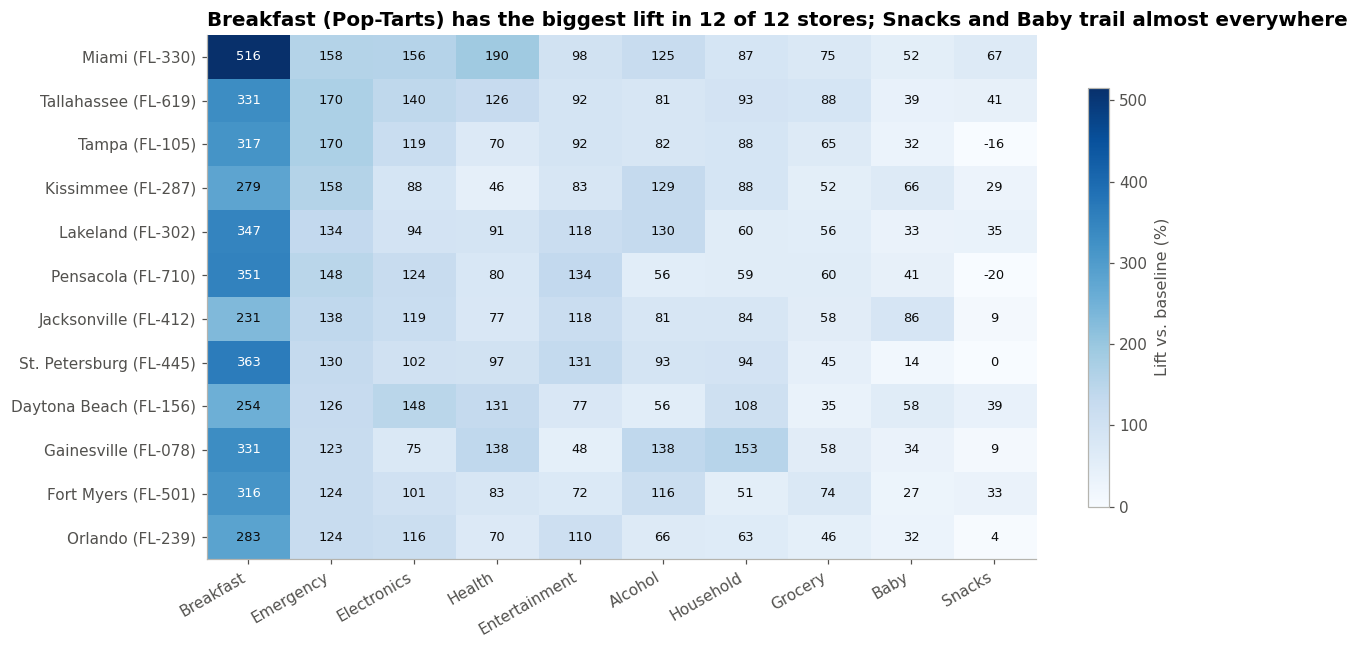

In [36]:
# Chart: category lift by store (heatmap, one sequential hue)
cat_store = 100 * (window_rate(dated_sales, SURGE_START, SURGE_END, ["store_id", "category"]) /
                   window_rate(dated_sales, BASELINE_START, BASELINE_END, ["store_id", "category"]) - 1)
hm = cat_store.unstack().loc[q4.index, cat_lift.index]
hm.index = [f"{q4.loc[s, 'city']} ({s})" for s in hm.index]
fig, ax = plt.subplots(figsize=(11.5, 6))
im = ax.imshow(hm.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(hm.shape[1]), hm.columns, rotation=30, ha="right")
ax.set_yticks(range(hm.shape[0]), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{int(round(v))}", ha="center", va="center", fontsize=8.5,
                color="white" if v > np.nanmax(hm.values) * 0.6 else "#0b0b0b")
ax.grid(False)
n_bfast = (hm.idxmax(axis=1) == "Breakfast").sum()
ax.set_title(f"Breakfast (Pop-Tarts) has the biggest lift in {n_bfast} of {len(hm)} stores; Snacks and Baby trail almost everywhere")
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Lift vs. baseline (%)")
plt.tight_layout(); plt.show()

### 7.1 Can the distribution centers keep up?
Exhibit 4 of the case and `distribution_centers.csv` give each DC's normal daily shipments and its surge maximum.
We assign each store to its nearest DC. The DC file has cities but no coordinates, so we used city-center coordinates.
Then we compare the demand multiple the stores saw with the multiple each DC can surge to.

**Assumptions (back-of-envelope):**
- A DC's normal shipments supply a normal day of demand at the stores it serves.
- Shipments scale one-for-one with units sold.
- Stores can hold stock that is shipped early.

In [37]:
dcs_raw = pd.read_csv(DATA_URL + urllib.parse.quote("distribution_centers (1).csv"), dtype=str)
dcs = dcs_raw.copy()
approx = dcs["surge_capacity"].str.contains("~", na=False)
dcs["surge_capacity"] = pd.to_numeric(dcs["surge_capacity"].str.replace("~", "", regex=False))
dcs["surge_capacity_approx"] = approx
for c in ["avg_daily_shipments", "distance_to_orlando_mi", "cost_per_shipment"]:
    dcs[c] = pd.to_numeric(dcs[c])
log_decision("dcs", "surge_capacity '~750' (Miami) read as 750 and flagged surge_capacity_approx", approx.sum(), len(dcs))
log_decision("dcs", "Birmingham cost_per_shipment is blank: left as NaN, not imputed", dcs["cost_per_shipment"].isna().sum(), len(dcs))

DC_COORDS = {"DC-JAX": (30.3322, -81.6557), "DC-ATL": (33.7490, -84.3880), "DC-DAL": (32.7767, -96.7970),
             "DC-MIA": (25.7617, -80.1918), "DC-BHM": (33.5186, -86.8104)}   # city centers
log_decision("dcs", "DC file has no coordinates: used city-center lat/lon to find each store's nearest DC", len(dcs), len(dcs))
dcs["lat"] = dcs["dc_id"].map(lambda k: DC_COORDS[k][0])
dcs["lon"] = dcs["dc_id"].map(lambda k: DC_COORDS[k][1])
dcs["surge_multiple"] = dcs["surge_capacity"] / dcs["avg_daily_shipments"]

dist = pd.DataFrame({dc.dc_id: haversine_mi(q4["latitude"], q4["longitude"], dc.lat, dc.lon) for dc in dcs.itertuples()})
q4["nearest_dc"] = dist.idxmin(axis=1)
q4["miles_to_dc"] = dist.min(axis=1)
dc_view = dcs.set_index("dc_id")[["city", "avg_daily_shipments", "surge_capacity", "surge_multiple", "cost_per_shipment"]]
dc_view["stores_served"] = q4.groupby("nearest_dc").size()
dc_view["store_list"] = q4.groupby("nearest_dc")["city"].agg(", ".join)
dc_view.fillna({"stores_served": 0, "store_list": "-"}).round(2)

,city,avg_daily_shipments,surge_capacity,surge_multiple,cost_per_shipment,stores_served,store_list
dc_id,,,,,,,
DC-JAX,Jacksonville,500,1000,2.00,245.0,9.0,"Tallahassee, Tampa, Kissimmee, Lakeland, Jacks..."
DC-ATL,Atlanta,400,700,1.75,412.5,0.0,-
DC-DAL,Dallas,300,600,2.00,687.0,0.0,-
DC-MIA,Miami,350,750,2.14,298.0,2.0,"Miami, Fort Myers"
DC-BHM,Birmingham,250,500,2.00,NaN,1.0,Pensacola


In [38]:
mult = daily_units / base.mean()                                  # statewide demand as a multiple of a normal day
served = dc_view[dc_view["stores_served"] > 0]
cap_mult = np.average(served["surge_multiple"], weights=served["stores_served"])
headroom = cap_mult - 1                                           # extra "normal days" of supply a DC can add per day
over_cap_days = mult[SURGE_START:SURGE_END][lambda s: s > cap_mult].index
extra_needed = (mult[SURGE_START:SURGE_END] - 1).clip(lower=0).sum()
start_early = min(1, headroom * ((SURGE_END - SURGE_START).days + 1) / extra_needed)
start_advisory = min(1, headroom * ((SURGE_END - NHC_FIRST_ADVISORY).days + 1) / extra_needed)
print(f"DCs serving these stores can surge to {cap_mult:.2f}x normal (store-weighted).")
print(f"Statewide demand was above that on {len(over_cap_days)} days: "
      f"{over_cap_days.min():%b %d}-{over_cap_days.max():%b %d}, peaking at {mult.max():.2f}x.")
print(f"Extra demand Sept 16-26 = {extra_needed:.1f} 'normal days' of volume.")
print(f"If DCs start surge shipping Sept 16 (first rise) and stores hold the stock: covers ~{start_early:.0%} of it.")
print(f"If DCs wait for the first NHC advisory (Sept 23): covers ~{start_advisory:.0%}.")

DCs serving these stores can surge to 2.02x normal (store-weighted).
Statewide demand was above that on 5 days: Sep 21-Sep 25, peaking at 3.57x.
Extra demand Sept 16-26 = 12.3 'normal days' of volume.
If DCs start surge shipping Sept 16 (first rise) and stores hold the stock: covers ~92% of it.
If DCs wait for the first NHC advisory (Sept 23): covers ~33%.


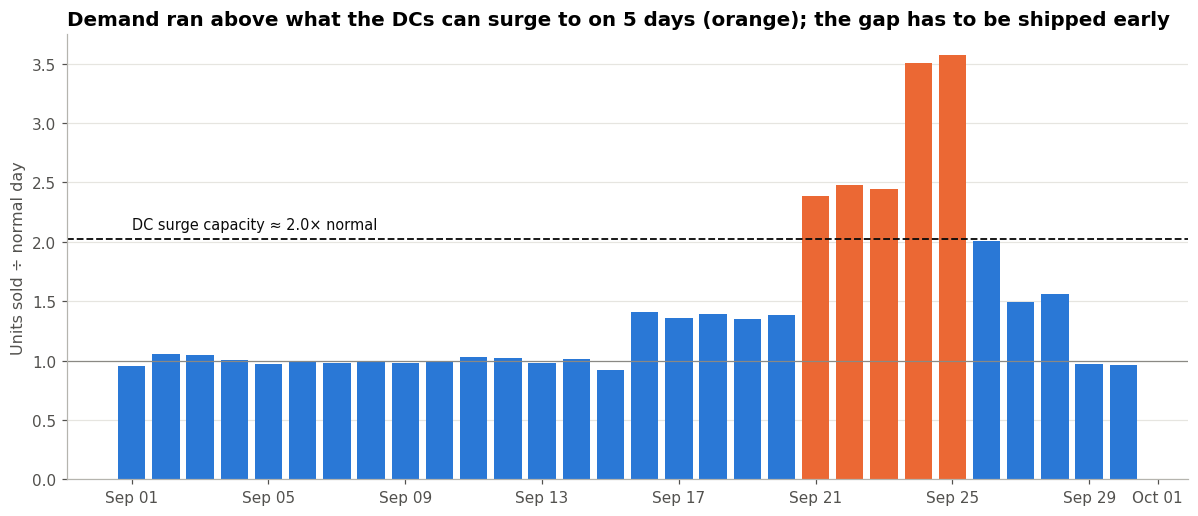

In [39]:
# Chart: demand multiple vs. DC surge capacity
fig, ax = plt.subplots(figsize=(11, 4.8))
colors = [PALETTE[1] if d in over_cap_days else PALETTE[0] for d in mult.index]
ax.bar(mult.index, mult.values, color=colors, width=0.8)
ax.axhline(cap_mult, color="#0b0b0b", lw=1.2, ls="--")
ax.text(mult.index[0], cap_mult + 0.08, f"DC surge capacity ≈ {cap_mult:.1f}× normal", fontsize=9.5, color="#0b0b0b")
ax.axhline(1, color=MUTED, lw=0.8)
ax.set_ylabel("Units sold ÷ normal day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title(f"Demand ran above what the DCs can surge to on {len(over_cap_days)} days (orange); "
             f"the gap has to be shipped early")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Q4 finding
*Every number here is printed by the cells above.*

**Every store surged, and by about the same amount.**
- **Lift (Sept 16–26 vs. baseline):** from **+95% (Orlando)** to **+140% (Miami)**. The coefficient of variation across stores is only 11%.
- **Peak (Sept 24–25):** every store ran at **3.0× to 3.9×** normal.
- **Start date:** the surge began the same week everywhere. It started on Sept 16 in 9 of 12 stores and on Sept 17–18 in the other three.
- **Category mix:** Breakfast (Pop-Tarts) had the biggest lift in every store, and Snacks and Baby trailed almost everywhere.

**Geography doesn't explain the differences.**
- **Distance from landfall:** r = +0.31, but Miami alone drives it. The rank correlation is −0.01.
- **The store's own storm gust:** r = −0.10.
- **The store's lowest pressure:** r = −0.07.

Three stores show it plainly:
- **Miami** was the farthest from landfall (363 miles), had only a 54 mph gust, and had the **biggest** lift.
- **Pensacola** got the weakest Helene winds (35 mph) and still rose **+110%**.
- **Tallahassee** was 46 miles from landfall with the lowest pressure (977 hPa), and rose **+128%**, close to Miami at the other end of the state.

This matches Q3: shoppers reacted to the **statewide forecast**, not to what the storm later did at their own store.

**The distribution network is the bottleneck.**
- **Who serves whom:** the nearest DCs are Jacksonville for 9 of the 12 stores, Miami for 2 and Birmingham for Pensacola. Atlanta ($412.50 per shipment) and Dallas ($687) are backup only, against $245 from Jacksonville.
- **Capacity vs. demand:** those DCs can surge to about **2.0×** normal. Statewide demand was above that for five straight days (**Sept 21–25**) and peaked at **3.6×**.
- **The shortfall:** extra demand over the window adds up to about **12.3 normal days** of volume.
  - If DCs start surge shipping when demand first rises (Sept 16) and stores hold the stock, they can cover about **92%** of it.
  - If they wait for the first NHC advisory (Sept 23), they cover about **33%**.

**What it means for leadership:**
- Allocate the surge to **every Florida store**, not just stores in the cone.
- Start surge shipping at the **first credible Florida threat**, about a week before landfall.
- Stage stock in stores during the early build, and pre-book Atlanta as overflow.

**Caveat:** the DC math is a ratio argument under the three assumptions above. These DCs serve far more than our 12 stores, so it shows the *shape* of the gap, not a truck count.

## 8. Q5: Signal or artifact? The board-game spike
**The question from the case.** Board-game sales are rising in storm regions. The Finance VP thinks it may be an artifact:
"Monopoly and card game bundles got lumped together." The CEO has 48 hours to decide whether to ship board games.

**How we test it.** An artifact leaves fingerprints, so we look for each one. All of the tests run in **SQL**. We copy the
SQLite database into memory, then add our clean `SKU_MAP` and the cleaned POS rows as tables so SQL can join across them.

| If it were an artifact... | Test |
|---|---|
| Only the POS extract would show it | Does the independent `daily_sales_summary` table show the same spike? |
| One mis-coded SKU would carry it | Lift for each Monopoly and card SKU separately |
| Bundles coded as Monopoly would change price or basket size | Transactions/day, units per transaction and price, baseline vs. surge |
| One store or register would cause it | Monopoly lift in each of the 12 stores |
| Stock wouldn't move | `inventory_levels` on-hand for board games vs. other categories |

In [40]:
db_path = os.path.join(DATA_DIR, "inventory_and_sales.db")
if not os.path.exists(db_path):
    urllib.request.urlretrieve(DATA_URL + urllib.parse.quote("inventory_and_sales (1).db"), db_path)
db = sqlite3.connect(":memory:")
with sqlite3.connect(db_path) as src:
    src.backup(db)                                    # work on an in-memory copy; the file on disk is never modified
SKU_MAP[["sku", "product_id", "product", "category"]].to_sql("sku_map", db, index=False)
(dated_sales.assign(date=dated_sales["date"].dt.strftime("%Y-%m-%d"))
 [["transaction_id", "date", "store_id", "sku", "product_id", "product_name", "category", "quantity", "unit_price"]]
 .to_sql("pos", db, index=False))

def sql(q):
    return pd.read_sql(q, db)

sql("""
SELECT 'daily_sales_summary' AS tbl, 'date stored as YYYYMMDD (not YYYY-MM-DD)' AS issue, COUNT(*) AS n_rows
  FROM daily_sales_summary WHERE date NOT LIKE '____-__-__'
UNION ALL
SELECT 'daily_sales_summary', 'negative total_revenue with positive units', COUNT(*)
  FROM daily_sales_summary WHERE total_revenue < 0 AND total_units > 0
UNION ALL
SELECT 'inventory_levels', 'SKU not in SKU_MAP (orphan)', COUNT(*)
  FROM inventory_levels i LEFT JOIN sku_map m ON i.sku = m.sku WHERE m.sku IS NULL
UNION ALL
SELECT 'inventory_levels', 'units_on_order is NULL', COUNT(*)
  FROM inventory_levels WHERE units_on_order IS NULL
""")

,tbl,issue,n_rows
0,daily_sales_summary,date stored as YYYYMMDD (not YYYY-MM-DD),218
1,daily_sales_summary,negative total_revenue with positive units,34
2,inventory_levels,SKU not in SKU_MAP (orphan),355
3,inventory_levels,units_on_order is NULL,626


In [41]:
# Clean views, in SQL
db.executescript("""
DROP VIEW IF EXISTS summary_clean;
CREATE VIEW summary_clean AS
SELECT CASE WHEN date LIKE '____-__-__' THEN date
            ELSE substr(date, 1, 4) || '-' || substr(date, 5, 2) || '-' || substr(date, 7, 2) END AS date,
       store_id, category, total_units,
       ABS(total_revenue) AS total_revenue,
       (total_revenue < 0) AS revenue_sign_fixed
FROM daily_sales_summary;

DROP VIEW IF EXISTS inventory_clean;
CREATE VIEW inventory_clean AS
SELECT i.date, i.store_id, i.sku, m.product, m.category, i.units_on_hand, i.units_on_order, i.reorder_point
FROM inventory_levels i JOIN sku_map m ON i.sku = m.sku;
""")
dup = sql("SELECT COUNT(*) AS n FROM (SELECT date, store_id, category FROM summary_clean GROUP BY 1, 2, 3 HAVING COUNT(*) > 1)")["n"][0]
grid_ok = sql("SELECT COUNT(DISTINCT date) AS days, COUNT(DISTINCT store_id) AS stores, COUNT(DISTINCT category) AS cats, COUNT(*) AS n FROM summary_clean")
assert dup == 0 and grid_ok.loc[0, "n"] == grid_ok.loc[0, "days"] * grid_ok.loc[0, "stores"] * grid_ok.loc[0, "cats"]
n_fmt = sql("SELECT COUNT(*) AS n FROM daily_sales_summary WHERE date NOT LIKE '____-__-__'")["n"][0]
n_neg = sql("SELECT SUM(revenue_sign_fixed) AS n FROM summary_clean")["n"][0]
n_orph = sql("SELECT COUNT(*) AS n FROM inventory_levels i LEFT JOIN sku_map m ON i.sku = m.sku WHERE m.sku IS NULL")["n"][0]
log_decision("db.daily_sales_summary", "Normalized YYYYMMDD dates to YYYY-MM-DD (no duplicates created; full 30x12x10 grid)", n_fmt, 3600)
log_decision("db.daily_sales_summary", "Negative total_revenue with positive units treated as a sign error: used ABS()", n_neg, 3600)
log_decision("db.inventory_levels", "Dropped rows whose SKU is not in SKU_MAP (UNKNOWN-99, LEGACY-PT, OLD-BATT-50, MISC-001)",
             n_orph, sql("SELECT COUNT(*) AS n FROM inventory_clean")["n"][0])
grid_ok

,days,stores,cats,n
0,30,12,10,3600


### 8.1 Test 1: does an independent source show the same spike?
`daily_sales_summary` is a separate table from the POS file, and its volumes are on a different (larger) scale, so we
compare **lift**, not levels.

In [42]:
LIFT_SQL = """
WITH w AS (
  SELECT category,
         SUM(CASE WHEN date BETWEEN '{b0}' AND '{b1}' THEN {u} END) / {nb}.0 AS base_per_day,
         SUM(CASE WHEN date BETWEEN '{s0}' AND '{s1}' THEN {u} END) / {ns}.0 AS surge_per_day
  FROM {t} GROUP BY category)
SELECT category, base_per_day, surge_per_day, 100.0 * (surge_per_day / base_per_day - 1) AS lift_pct FROM w
"""
win = dict(b0=f"{BASELINE_START:%Y-%m-%d}", b1=f"{BASELINE_END:%Y-%m-%d}", s0=f"{SURGE_START:%Y-%m-%d}", s1=f"{SURGE_END:%Y-%m-%d}",
           nb=(BASELINE_END - BASELINE_START).days + 1, ns=(SURGE_END - SURGE_START).days + 1)
db_lift = sql(LIFT_SQL.format(t="summary_clean", u="total_units", **win)).set_index("category")
pos_lift = sql(LIFT_SQL.format(t="pos", u="quantity", **win)).set_index("category")
daily_db = sql("SELECT date, category, SUM(total_units) AS u FROM summary_clean GROUP BY 1, 2").pivot(index="date", columns="category", values="u")
daily_pos = sql("SELECT date, category, SUM(quantity) AS u FROM pos GROUP BY 1, 2").pivot(index="date", columns="category", values="u")
xcheck = pd.DataFrame({
    "lift_pct (summary table)": db_lift["lift_pct"],
    "lift_pct (POS transactions)": pos_lift["lift_pct"],
    "daily correlation": [daily_db[c].corr(daily_pos[c]) for c in db_lift.index],
}).round(2)
xcheck["gap_pts"] = (xcheck["lift_pct (summary table)"] - xcheck["lift_pct (POS transactions)"]).round(1)
xcheck.sort_values("lift_pct (POS transactions)", ascending=False)

,lift_pct (summary table),lift_pct (POS transactions),daily correlation,gap_pts
category,,,,
Breakfast,179.69,321.41,0.98,-141.7
Emergency,145.84,141.44,0.97,4.4
Electronics,75.54,113.07,0.91,-37.5
Health,91.50,97.67,0.93,-6.2
Entertainment,106.95,96.62,0.96,10.3
Alcohol,85.83,94.30,0.93,-8.5
Household,76.73,83.29,0.95,-6.6
Grocery,45.43,58.67,0.84,-13.2
Baby,37.89,42.10,0.84,-4.2


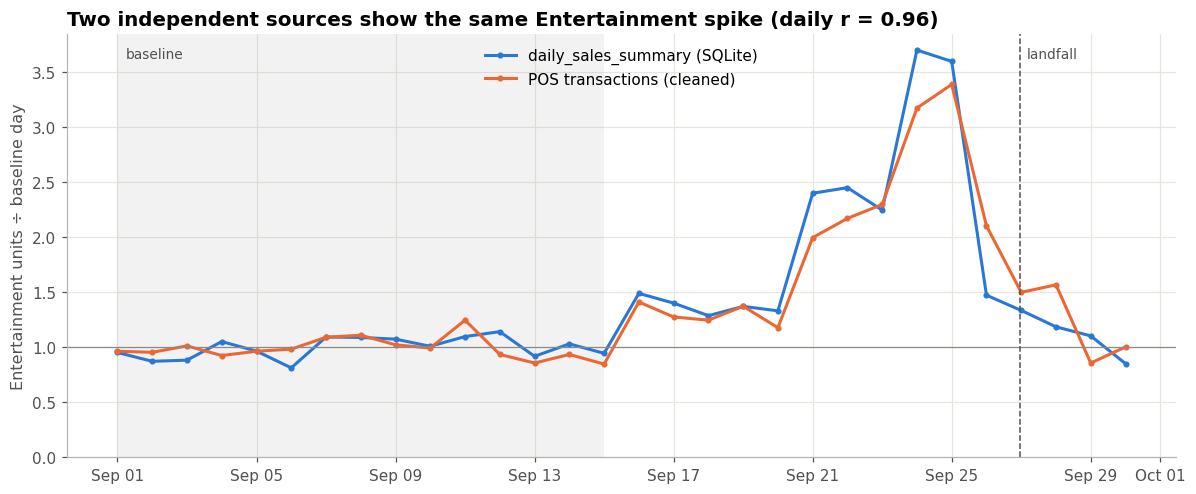

In [43]:
# Chart: Entertainment, two sources, same baseline-indexed scale
idx = lambda s: s / s.loc[win["b0"]:win["b1"]].mean()
ent = pd.DataFrame({"daily_sales_summary (SQLite)": idx(daily_db["Entertainment"]),
                    "POS transactions (cleaned)": idx(daily_pos["Entertainment"])})
ent.index = pd.to_datetime(ent.index)
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, c in enumerate(ent.columns):
    ax.plot(ent.index, ent[c], color=PALETTE[i], marker="o", ms=3, label=c)
ax.axhline(1, color=MUTED, lw=0.8)
ax.set_ylabel("Entertainment units ÷ baseline day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylim(0)
shade_windows(ax)
ax.set_title(f"Two independent sources show the same Entertainment spike "
             f"(daily r = {xcheck.loc['Entertainment', 'daily correlation']:.2f})")
ax.legend(loc="upper center")
plt.tight_layout(); plt.show()

### 8.2 Tests 2–4: one bad SKU, bundles, or one store?

In [44]:
sku_test = sql(f"""
SELECT p.product_name AS product, p.sku,
       SUM(CASE WHEN date BETWEEN '{win['b0']}' AND '{win['b1']}' THEN quantity END) / {win['nb']}.0 AS base_per_day,
       SUM(CASE WHEN date BETWEEN '{win['s0']}' AND '{win['s1']}' THEN quantity END) / {win['ns']}.0 AS surge_per_day
FROM pos p
WHERE p.category = 'Entertainment'
GROUP BY 1, 2 ORDER BY 1, 2
""")
sku_test["lift_pct"] = 100 * (sku_test["surge_per_day"] / sku_test["base_per_day"] - 1)
sku_test.round(1)

,product,sku,base_per_day,surge_per_day,lift_pct
0,Monopoly Board Game,BG-MONO,13.8,31.3,126.8
1,Monopoly Board Game,GAME-MONO,15.9,33.2,109.3
2,Monopoly Board Game,MONOPOLY-01,13.8,32.5,135.4
3,Playing Cards,CARDS-01,29.7,47.9,61.2
4,Playing Cards,PLAYCARD-STD,29.5,57.0,93.2


In [45]:
basket = sql(f"""
SELECT product_name AS product,
       CASE WHEN date BETWEEN '{win['b0']}' AND '{win['b1']}' THEN 'baseline' ELSE 'surge' END AS period,
       COUNT(DISTINCT transaction_id) * 1.0 /
         CASE WHEN date BETWEEN '{win['b0']}' AND '{win['b1']}' THEN {win['nb']} ELSE {win['ns']} END AS transactions_per_day,
       AVG(quantity) AS units_per_transaction,
       AVG(unit_price) AS avg_price,
       MIN(unit_price) AS min_price, MAX(unit_price) AS max_price
FROM pos
WHERE product_name IN ('Monopoly Board Game', 'Playing Cards')
  AND (date BETWEEN '{win['b0']}' AND '{win['b1']}' OR date BETWEEN '{win['s0']}' AND '{win['s1']}')
GROUP BY 1, 2 ORDER BY 1, 2
""")
basket.round(2)

,product,period,transactions_per_day,units_per_transaction,avg_price,min_price,max_price
0,Monopoly Board Game,baseline,28.43,1.53,20.01,18.99,20.98
1,Monopoly Board Game,surge,64.73,1.50,20.00,18.99,20.98
2,Playing Cards,baseline,29.57,2.00,4.99,4.74,5.24
3,Playing Cards,surge,52.18,2.01,5.00,4.74,5.24


In [46]:
by_store = sql(f"""
SELECT store_id,
       SUM(CASE WHEN date BETWEEN '{win['b0']}' AND '{win['b1']}' THEN quantity END) / {win['nb']}.0 AS base_per_day,
       SUM(CASE WHEN date BETWEEN '{win['s0']}' AND '{win['s1']}' THEN quantity END) / {win['ns']}.0 AS surge_per_day
FROM pos WHERE product_name = 'Monopoly Board Game'
GROUP BY 1
""")
by_store["lift_pct"] = 100 * (by_store["surge_per_day"] / by_store["base_per_day"] - 1)
by_store = by_store.merge(stores[["store_id", "city"]]).sort_values("lift_pct")
print(f"Monopoly lift is positive in {(by_store['lift_pct'] > 0).sum()} of {len(by_store)} stores "
      f"(range {by_store['lift_pct'].min():.0f}% to {by_store['lift_pct'].max():.0f}%)")
by_store.round(1)

Monopoly lift is positive in 12 of 12 stores (range 56% to 218%)


,store_id,base_per_day,surge_per_day,lift_pct,city
0,FL-078,3.8,5.9,56.1,Gainesville
2,FL-156,3.9,6.8,76.8,Daytona Beach
6,FL-330,3.7,6.7,81.1,Miami
10,FL-619,4.1,8.0,93.1,Tallahassee
9,FL-501,3.5,7.3,107.8,Fort Myers
4,FL-287,3.6,8.1,122.1,Kissimmee
3,FL-239,3.6,8.1,126.5,Orlando
7,FL-412,4.1,9.3,127.8,Jacksonville
5,FL-302,3.6,9.3,159.6,Lakeland
1,FL-105,3.1,8.3,163.2,Tampa


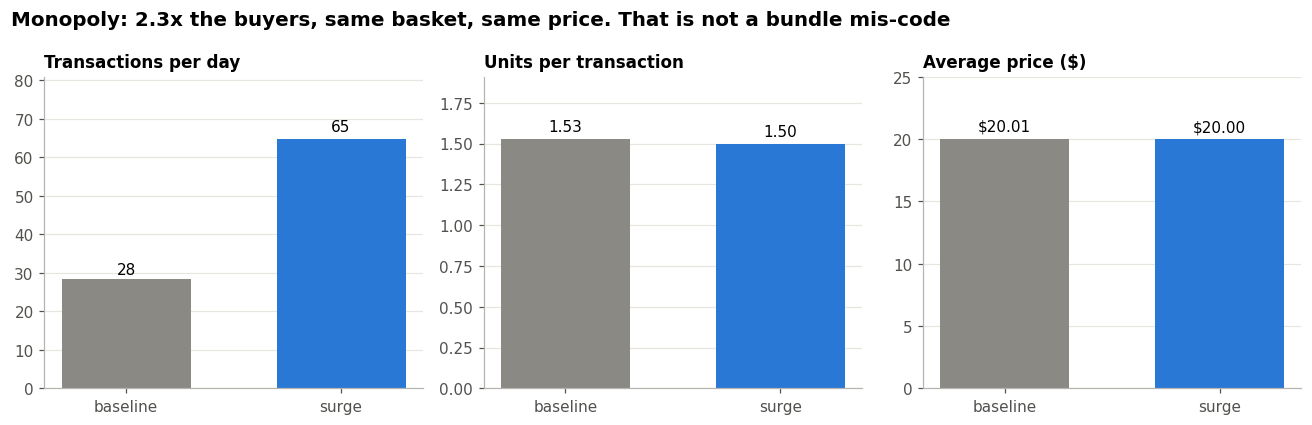

In [47]:
# Chart: the bundle fingerprint test, three small panels
m = basket[basket["product"] == "Monopoly Board Game"].set_index("period")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, (col, label, fmt) in zip(axes, [("transactions_per_day", "Transactions per day", "{:.0f}"),
                                         ("units_per_transaction", "Units per transaction", "{:.2f}"),
                                         ("avg_price", "Average price ($)", "${:.2f}")]):
    ax.bar(m.index, m[col], color=[MUTED, PALETTE[0]], width=0.6)
    for i, v in enumerate(m[col]):
        ax.text(i, v * 1.02, fmt.format(v), ha="center", va="bottom", fontsize=10)
    ax.set_title(label, fontsize=11)
    ax.set_ylim(0, m[col].max() * 1.25)
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Monopoly: {m.loc['surge', 'transactions_per_day'] / m.loc['baseline', 'transactions_per_day']:.1f}x the buyers, same basket, same price. That is not a bundle mis-code",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

### 8.3 Test 5: does the inventory table confirm it?

In [48]:
inv = sql("""
SELECT category,
       CASE WHEN date <= '2024-09-15' THEN '1 baseline (Sep 1-15)'
            WHEN date <= '2024-09-20' THEN '2 early build (Sep 16-20)'
            WHEN date <= '2024-09-26' THEN '3 surge (Sep 21-26)'
            ELSE '4 after (Sep 27-30)' END AS phase,
       AVG(units_on_hand) AS avg_on_hand,
       AVG(units_on_hand < reorder_point) AS share_below_reorder_point,
       COUNT(*) AS records
FROM inventory_clean
GROUP BY 1, 2
""")
on_hand = inv.pivot(index="category", columns="phase", values="avg_on_hand")
on_hand["surge vs baseline"] = on_hand.iloc[:, 2] / on_hand.iloc[:, 0] - 1
on_hand.sort_values("surge vs baseline").round(2)

phase,1 baseline (Sep 1-15),2 early build (Sep 16-20),3 surge (Sep 21-26),4 after (Sep 27-30),surge vs baseline
category,,,,,
Baby,85.45,133.84,32.71,66.34,-0.62
Electronics,79.78,115.87,34.49,69.43,-0.57
Entertainment,83.09,135.95,37.07,60.22,-0.55
Emergency,81.12,122.33,37.29,67.34,-0.54
Breakfast,81.07,118.27,37.58,68.14,-0.54
Alcohol,80.86,115.91,38.55,72.50,-0.52
Health,74.98,125.07,35.91,45.88,-0.52
Snacks,83.59,120.97,40.06,70.22,-0.52
Household,78.78,135.41,40.28,59.60,-0.49


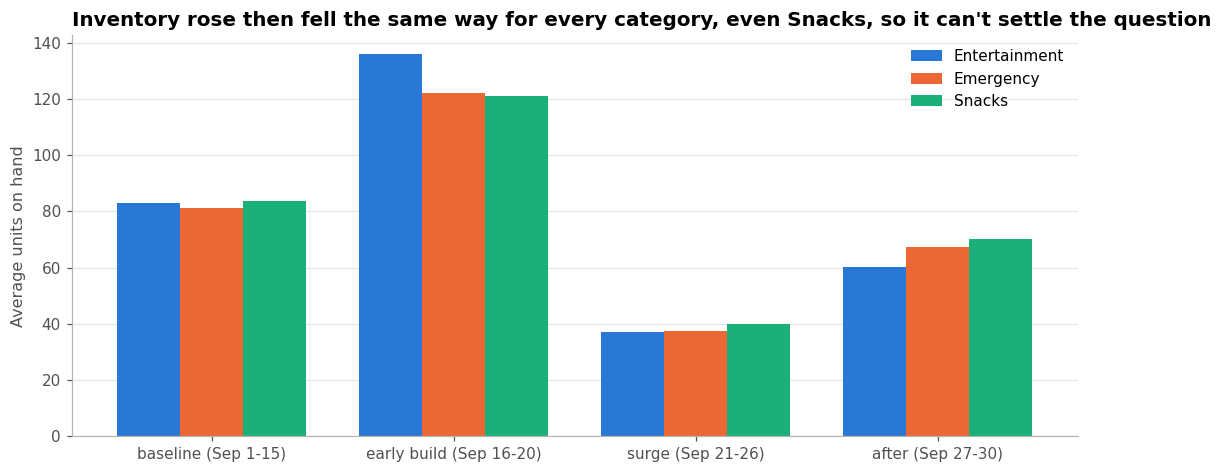

In [49]:
# Chart: on-hand by phase for board games vs. the category that surged most vs. the one that barely moved
show = ["Entertainment", "Emergency", "Snacks"]
fig, ax = plt.subplots(figsize=(10, 4.4))
phases = on_hand.columns[:4]
x = np.arange(len(phases)); w = 0.26
for i, c in enumerate(show):
    ax.bar(x + (i - 1) * w, on_hand.loc[c, phases], width=w, color=PALETTE[i], label=c)
ax.set_xticks(x, [p[2:] for p in phases])
ax.set_ylabel("Average units on hand")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Inventory rose then fell the same way for every category, even Snacks, so it can't settle the question")
plt.tight_layout(); plt.show()

### 8.4 Scorecard and sizing the bet

In [50]:
mono = prod_lift.loc["Monopoly Board Game"]
cards = prod_lift.loc["Playing Cards"]
mono_daily = dated_sales[dated_sales["product_name"] == "Monopoly Board Game"].groupby("date")["quantity"].sum()
mono_peak_x = mono_daily[PEAK[0]:PEAK[1]].mean() / mono_daily[BASELINE_START:BASELINE_END].mean()
mono_after_x = mono_daily["2024-09-27":"2024-09-28"].mean() / mono_daily[BASELINE_START:BASELINE_END].mean()
mb, ms = m.loc["baseline"], m.loc["surge"]
mono_skus = sku_test[sku_test["product"] == "Monopoly Board Game"]["lift_pct"]
ent_x = xcheck.loc["Entertainment"]
scorecard = pd.DataFrame([
    ["Independent source", "Spike only in POS", f"Summary table +{ent_x['lift_pct (summary table)']:.0f}% vs POS +{ent_x['lift_pct (POS transactions)']:.0f}%, daily r = {ent_x['daily correlation']:.2f}", "Signal"],
    ["One mis-coded SKU", "One SKU carries the lift", f"All 3 Monopoly SKUs +{mono_skus.min():.0f}% to +{mono_skus.max():.0f}%", "Signal"],
    ["Bundles coded as Monopoly", "Price or basket size shifts", f"{mb['transactions_per_day']:.0f} -> {ms['transactions_per_day']:.0f} transactions/day; {mb['units_per_transaction']:.2f} -> {ms['units_per_transaction']:.2f} units each; ${mb['avg_price']:.2f} -> ${ms['avg_price']:.2f}", "Signal"],
    ["One store or register", "Concentrated in a few stores", f"Up in {(by_store['lift_pct'] > 0).sum()}/12 stores ({by_store['lift_pct'].min():.0f}% to {by_store['lift_pct'].max():.0f}%)", "Signal"],
    ["Inventory moves", "Stock flat while 'sales' spike", "On-hand fell for every category, Snacks included", "Inconclusive"],
], columns=["test", "artifact would look like", "what we see", "verdict"])
with pd.option_context("display.max_colwidth", 120):
    display(scorecard)
print(f"Monopoly: +{mono['lift_pct']:.0f}% over the window, {mono_peak_x:.1f}x on Sept 24-25, {mono_after_x:.1f}x on Sept 27-28 | "
      f"Playing cards: +{cards['lift_pct']:.0f}%")
print(f"In this 12-store POS sample: Monopoly {mono['baseline_units_per_day']:.0f} -> {mono['surge_units_per_day']:.0f} units/day "
      f"(+{mono['extra_units_per_day']:.0f}/day, about {mono['extra_units_per_day'] / 12:.1f} extra per store per day)")
print("Cheapest DCs per shipment:", dcs.dropna(subset=["cost_per_shipment"]).sort_values("cost_per_shipment")[["dc_id", "cost_per_shipment"]].head(3).to_dict("records"))

,test,artifact would look like,what we see,verdict
0,Independent source,Spike only in POS,"Summary table +107% vs POS +97%, daily r = 0.96",Signal
1,One mis-coded SKU,One SKU carries the lift,All 3 Monopoly SKUs +109% to +135%,Signal
2,Bundles coded as Monopoly,Price or basket size shifts,28 -> 65 transactions/day; 1.53 -> 1.50 units each; $20.01 -> $20.00,Signal
3,One store or register,Concentrated in a few stores,Up in 12/12 stores (56% to 218%),Signal
4,Inventory moves,Stock flat while 'sales' spike,"On-hand fell for every category, Snacks included",Inconclusive


Monopoly: +123% over the window, 4.0x on Sept 24-25, 1.5x on Sept 27-28 | Playing cards: +77%
In this 12-store POS sample: Monopoly 43 -> 97 units/day (+54/day, about 4.5 extra per store per day)
Cheapest DCs per shipment: [{'dc_id': 'DC-JAX', 'cost_per_shipment': 245.0}, {'dc_id': 'DC-MIA', 'cost_per_shipment': 298.0}, {'dc_id': 'DC-ATL', 'cost_per_shipment': 412.5}]


### Q5 finding
*Every number here is printed by the cells above.*

**Verdict: the board-game spike is a real signal, not an artifact, but it is smaller than the headline.** Four of five tests say "signal". The fifth can't tell.

1. **Independent source.** The SQLite `daily_sales_summary` shows Entertainment up **+107%**, against **+97%** in the POS file, with a daily correlation of **0.96**. A POS coding error wouldn't show up in a separate table.
2. **One mis-coded SKU?** No. All three Monopoly SKUs rose by similar amounts (**+109% to +135%**). Separately, our SKU consolidation never linked a card SKU to a Monopoly SKU, because cashiers never used a shared name.
3. **Bundles coded as Monopoly?** No.
   - Monopoly transactions went from **28 to 65 a day (2.3×)**.
   - Units per transaction stayed flat (**1.53 → 1.50**).
   - The average price stayed flat (**$20.01 → $20.00**), and so did the price range.
   - A bundle being rung up as Monopoly would shift the price or the basket size. Neither moved. These were more people buying the same game.
4. **One store or register?** No. Monopoly rose in **12 of 12 stores**, from +56% to +218%.
5. **Inventory: inconclusive.** On-hand rose 43–72% during the early build and then fell 48–62% during the surge for **every** category. That includes Snacks, whose sales barely moved (+17%). The table shows a network-wide restock-and-draw-down pattern, so it can't single out board games. We don't count it either way.

**How big is the signal?** Monopoly ran **+123%** over Sept 16–26 (about **2.2×** normal), **4.0×** on the Sept 24–25 peak, and still **1.5×** for two days after landfall. Playing cards were **+77%**. The case exhibit's "+250%" sits between our window average and our peak. The real overstatement risk is *which window you quote*, not the sales themselves.

**A flag for the data team.** The summary table and POS mostly agree:
- **Close agreement:** most categories, including Emergency and Entertainment, agree within about 10 points.
- **Big gaps:** Breakfast (+180% in the summary table vs. +321% in POS) and Electronics (+76% vs. +113%).

For Pop-Tarts we trust the POS figure, because we consolidated its four SKUs ourselves. The summary table's category roll-up can't be audited at SKU level.

**Recommendation for the CEO's 48-hour decision: ship board games, sized to the measured lift.**
- **How much:** plan for about **2.2×** normal game volume across the window and about **4×** on the two peak days. In this 12-store sample that is about **54 extra Monopoly units a day**, roughly 4–5 per store.
- **Priority:** load them after Emergency and Pop-Tarts.
- **Where from:** ship from **Jacksonville ($245 per shipment)** or **Miami ($298)**, not Dallas ($687).
- **Downside:** the Finance VP's risk is limited. Board games don't spoil, and demand held at 1.5× after landfall, so leftover units can be sold rather than written off.

## 9. What we tell leadership (Q1–Q5)
1. **Move on the forecast, not the weather.**
   - Buying started about 10 days before landfall and peaked 2 days before it, while skies were still calm (Q1).
   - Sales track gusts and pressure *two days ahead* (r = 0.71 and −0.76), not same-day weather (r ≈ 0.2) (Q3).
2. **Stock Emergency and Pop-Tarts first.** Emergency adds the most units, about 500 extra a day. Pop-Tarts has the biggest jump, about 8× normal at the peak. Electronics, Health and Entertainment come next (Q1).
3. **Send it to every Florida store.** The surge was statewide and almost uniform: +95% to +140% per store, no matter the distance from landfall or the local wind (Q4).
4. **Start surge shipping about a week out.** Demand hit 3.6× normal, but the DCs can surge to only about 2×. Shipping from the first rise covers about 92% of the extra demand. Waiting for the NHC advisory covers about 33% (Q4).
5. **Board games: yes, but size them right.** The spike is real: it shows in two independent sources and in all 12 stores, with the same price and basket. Plan for about 2.2× normal, about 4× on the peak days, shipped from Jacksonville or Miami (Q5).
6. **Fix the data that nearly fooled us.**
   - Keep the SKU→product map in the ETL. Without it, Pop-Tarts looks like four ordinary items (Q2).
   - Don't trust catalog costs yet (Q2).
   - Reconcile the summary table's Breakfast and Electronics roll-ups with POS (Q5).

In [51]:
# Full decision log across every file (section 2.3 shows only the transaction and store steps)
with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame(decision_log))
print("Notebook finished:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| decisions logged:", len(decision_log))

,step,decision,rows_touched,rows_after
0,duplicates,Dropped exact duplicate rows (same transaction_id and every field),30,25532
1,store_id,"Stripped spaces, upper-cased, rewrote to FL-### (60 spellings -> 12 stores)",4345,25532
2,unit_price,Removed leading '$' and converted text to float,3026,25532
3,quantity,"Negative quantities treated as returns: kept, flagged is_return=True, excluded from demand counts",130,25532
4,timestamp,Parsed 5 text formats to datetime (store-local time),12479,25532
5,timestamp,"Missing timestamps flagged (timestamp_missing=True), not dropped: still count for SKU/product totals, left out of anything time-based",884,25532
6,category,Mapped 37 category spellings to 10 categories,18744,25532
7,sku,"Mapped 45 SKUs to 20 products via SKU_MAP; canonical name in product_name, original kept in product_name_raw",17319,25532
8,stores,"Normalized store ids and dropped repeat stores (FL239 = FL-239, FL_287 = FL-287)",2,12
9,stores,Set state 'Florida' / 'Fla.' to 'FL',4,12


Notebook finished: 2026-10-22 17:41 | decisions logged: 18
